# Distribuciones de skims y viajes: base anterior contra base nueva

- **Base anterior:** skims de `skim_matrices` (las del filtro 1), sin pares imposibles
- **Base nueva:** skims del 27/10/26 (`skim_matrices/skims_271026`), que no tiene pares imposibles

Variables: TTC (min), DIST (km) y velocidad DIST / TTC (km/h). Se excluyen los viajes intrazonales.

En cada gráfica las barras son el % de cada intervalo y la leyenda dice a cuánto equivale el 100 %. En tiempo, la última barra (120+) junta todo lo de más de 120 min; en distancia, la última (60+) junta todo lo de más de 60 km.

In [1]:
%matplotlib inline

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from IPython.display import display

In [2]:
BASE = r"C:\proyectos\red-vial-guadalajara"
SKIM_MATRICES = os.path.join(BASE, "skim_matrices")
CARPETAS = {"Base anterior": SKIM_MATRICES, "Base nueva": os.path.join(SKIM_MATRICES, "skims_271026")}
DEMANDA = os.path.join(BASE, "demanda_pf", "Demanda x PF")
SHAPE = os.path.join(SKIM_MATRICES, "zonas_2105", "zonas_2105.shp")
R_TABLAS = os.path.join(SKIM_MATRICES, "resultados_filtro_2", "tablas")

PERIODOS = ["AP", "LM", "EA", "PP"]
MODOS = ["VP", "HEAVY_FREIGHT", "LIGHT_FREIGHT"]
NOMBRES_MODO = {"VP": "Autos (VP)", "HEAVY_FREIGHT": "Carga pesada", "LIGHT_FREIGHT": "Carga ligera"}
COLORES = {"Base anterior": "#9aa5b1", "Base nueva": "#4c72b0"}

# Mismas reglas de pares imposibles que los notebooks del filtro
SIN_RUTA = 999999
TTC_MIN = 0.5                                           # min
VEL_MIN = 5                                             # km/h
VEL_MAX_POR_DIST = [(2, 60), (10, 80), (np.inf, 110)]   # (DIST hasta km, velocidad máxima en km/h)
FACTOR_RECTA_MIN = 0.5

VARIABLES = {
    "TTC": ("Tiempo", list(range(0, 125, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 120, 5)] + ["120+"], "min"),
    "DIST": ("Distancia", list(range(0, 65, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 60, 5)] + ["60+"], "km"),
    "VEL": ("Velocidad", list(range(0, 115, 5)), [f"{i}-{i+5}" for i in range(0, 110, 5)], "km/h"),
}
PERCENTILES = [5, 10, 25, 50, 75, 90, 95, 99]

In [3]:
# Fila i de la skim = zona zonas[i] (id_visum de menor a mayor), igual que en los notebooks del filtro
zonas_geo = gpd.read_file(SHAPE)
zonas = sorted(zonas_geo["id_visum"].tolist())
posicion = {z: i for i, z in enumerate(zonas)}
municipio = zonas_geo.set_index("id_visum")["nombre_mun"]
centros = zonas_geo.set_index("id_visum").geometry.centroid.reindex(zonas)
centro_x, centro_y = centros.x.to_numpy(), centros.y.to_numpy()

## Bases de datos

In [4]:
def leer_skim(carpeta, tipo, p):
    return pd.read_csv(os.path.join(carpeta, f"{tipo}_{p}.csv"), index_col=0).to_numpy()


def vel_maxima(dist):
    return np.select([dist <= hasta for hasta, _ in VEL_MAX_POR_DIST], [vel for _, vel in VEL_MAX_POR_DIST],
                     default=VEL_MAX_POR_DIST[-1][1])


def pares(ttc, dist, o, d):
    """TTC, DIST y velocidad de los pares (o, d), con la marca de par válido (con ruta y sin reglas de imposible)."""
    t = pd.DataFrame({"Origin": o, "Destination": d, "TTC": ttc[o, d], "DIST": dist[o, d]})
    con_ruta = (o != d) & (t["TTC"] < SIN_RUTA) & (t["DIST"] < SIN_RUTA)
    t["VEL"] = (t["DIST"] / (t["TTC"] / 60)).where(con_ruta & (t["TTC"] > 0))
    recta = np.hypot(centro_x[o] - centro_x[d], centro_y[o] - centro_y[d]) / 1000
    imposible = ((t["TTC"] == 0) & (t["DIST"] > 0)) | ((t["TTC"] > 0) & (t["TTC"] < TTC_MIN)) | (t["VEL"] < VEL_MIN) \
        | (t["VEL"] > vel_maxima(t["DIST"])) | (t["DIST"] < FACTOR_RECTA_MIN * recta)
    t["valido"] = con_ruta & ~imposible
    return t


def cargar_demanda(p, intrazonales=False):
    """Viajes por par de zonas y tipo de vehículo, con la fila de la skim."""
    d = pd.concat([pd.read_csv(os.path.join(DEMANDA, f"matriz_{m}_{p}.csv")).assign(Modo=m) for m in MODOS])
    d = d.pivot_table(index=["Origen_ageb", "Destino_ageb"], columns="Modo", values="Ponderador_x_PF",
                      aggfunc="sum", fill_value=0).reindex(columns=MODOS, fill_value=0).reset_index().rename_axis(columns=None)
    d["Trips"] = d[MODOS].sum(axis=1)
    d["Origin"] = d["Origen_ageb"].map(posicion)
    d["Destination"] = d["Destino_ageb"].map(posicion)
    d = d.dropna(subset=["Origin", "Destination"]).astype({"Origin": int, "Destination": int})
    if not intrazonales:
        d = d[d["Origin"] != d["Destination"]]
    return d.reset_index(drop=True)

In [5]:
skims = {}    # (base, periodo): pares válidos entre los que tienen ruta en la base nueva
viajes = {}   # (base, periodo): pares con viajes y válidos en esa base
filas_carga = []
for p in PERIODOS:
    demanda = cargar_demanda(p)
    matrices = {base: (leer_skim(c, "TTC", p), leer_skim(c, "DIST", p)) for base, c in CARPETAS.items()}

    # Para comparar las skims se usan los mismos pares en las dos bases: los que tienen ruta en la base nueva
    ttc_n, dist_n = matrices["Base nueva"]
    o, d = np.nonzero(~np.eye(len(ttc_n), dtype=bool) & (ttc_n < SIN_RUTA) & (dist_n < SIN_RUTA))

    fila = {"Periodo": p, "Pares con ruta en la base nueva": len(o), "Viajes (sin intrazonales)": demanda["Trips"].sum()}
    for base, (ttc, dist) in matrices.items():
        sk = pares(ttc, dist, o, d)
        skims[(base, p)] = sk[sk["valido"]]
        v = pares(ttc, dist, demanda["Origin"].to_numpy(), demanda["Destination"].to_numpy())
        v = v.join(demanda[MODOS + ["Trips"]])
        viajes[(base, p)] = v[v["valido"]]
        fila[f"Pares válidos, {base.lower()}"] = int(sk["valido"].sum())
        fila[f"Viajes en pares válidos, {base.lower()}"] = v.loc[v["valido"], "Trips"].sum()
    filas_carga.append(fila)
    del matrices

pd.DataFrame(filas_carga).round(1)

,Periodo,Pares con ruta en la base nueva,Viajes (sin intrazonales),"Pares válidos, base anterior","Viajes en pares válidos, base anterior","Pares válidos, base nueva","Viajes en pares válidos, base nueva"
0,AP,8405,346952.9,7554,304316.7,8405,345836.7
1,LM,4209,165861.4,3509,136155.6,4209,163192.7
2,EA,12264,287968.1,10891,248907.9,12264,285530.6
3,PP,5663,282023.6,4969,244115.7,5663,280682.8


- Los pares de las skims son los mismos en las dos bases: los que tienen ruta en la base nueva (solo trae ruta en los pares con demanda). En la base anterior se quitan los que eran imposibles.
- Los viajes son los de la demanda en pares válidos de cada base.

## Base usada y cobertura de la skim
Archivos que se leen (la base nueva es la del zip Skims_271026) y qué parte de todos los pares de la skim tiene ruta y viajes.

In [6]:
from datetime import datetime

archivos = pd.DataFrame([
    {"Base": base, "Archivo": f"{tipo}_{p}.csv", "Carpeta": carpeta,
     "Modificado": datetime.fromtimestamp(os.path.getmtime(os.path.join(carpeta, f"{tipo}_{p}.csv"))).strftime("%Y-%m-%d %H:%M"),
     "MB": round(os.path.getsize(os.path.join(carpeta, f"{tipo}_{p}.csv")) / 1e6, 1)}
    for base, carpeta in CARPETAS.items() for tipo in ["TTC", "DIST"] for p in PERIODOS
])
archivos

,Base,Archivo,Carpeta,Modificado,MB
0,Base anterior,TTC_AP.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.3
1,Base anterior,TTC_LM.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.6
2,Base anterior,TTC_EA.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.5
3,Base anterior,TTC_PP.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.4
4,Base anterior,DIST_AP.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.8
5,Base anterior,DIST_LM.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.8
6,Base anterior,DIST_EA.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.8
7,Base anterior,DIST_PP.csv,C:\proyectos\red-vial-guadalajara\skim_matrices,2026-10-08 15:10,81.8
8,Base nueva,TTC_AP.csv,C:\proyectos\red-vial-guadalajara\skim_matrice...,2026-10-29 19:54,40.0
9,Base nueva,TTC_LM.csv,C:\proyectos\red-vial-guadalajara\skim_matrice...,2026-10-29 19:55,39.9


In [7]:
filas_cob = []
for p in PERIODOS:
    demanda = cargar_demanda(p, intrazonales=True)
    o, d = demanda["Origin"].to_numpy(), demanda["Destination"].to_numpy()
    intra = o == d
    for base, carpeta in CARPETAS.items():
        ttc, dist = leer_skim(carpeta, "TTC", p), leer_skim(carpeta, "DIST", p)
        n = ttc.size
        fuera = ~np.eye(len(ttc), dtype=bool)
        con_ruta = fuera & (ttc < SIN_RUTA) & (dist < SIN_RUTA)
        con_viajes = np.zeros_like(con_ruta)
        con_viajes[o[~intra], d[~intra]] = True
        ruta_par = con_ruta[o, d]
        filas_cob.append({
            "Periodo": p, "Base": base,
            "Pares de la skim": n,
            "Pares fuera de la diagonal": int(fuera.sum()),
            "Pares con ruta": int(con_ruta.sum()),
            "% de la skim con ruta": con_ruta.sum() / n * 100,
            "Pares con viajes (sin intrazonales)": int(con_viajes.sum()),
            "% de la skim con viajes": con_viajes.sum() / n * 100,
            "Pares con viajes y con ruta": int((con_viajes & con_ruta).sum()),
            "Pares con viajes sin ruta": int((con_viajes & ~con_ruta).sum()),
            "Pares con ruta sin viajes": int((con_ruta & ~con_viajes).sum()),
            "% de los pares con ruta que tiene viajes": (con_viajes & con_ruta).sum() / con_ruta.sum() * 100,
            "Viajes totales": demanda["Trips"].sum(),
            "Viajes intrazonales": demanda.loc[intra, "Trips"].sum(),
            "Viajes en pares con ruta": demanda.loc[~intra & ruta_par, "Trips"].sum(),
            "Viajes en pares sin ruta": demanda.loc[~intra & ~ruta_par, "Trips"].sum(),
        })
        del ttc, dist, con_ruta, con_viajes

cobertura = pd.DataFrame(filas_cob).set_index(["Periodo", "Base"])
cobertura.round(3).T

Periodo                                             AP               \
Base                                     Base anterior   Base nueva   
Pares de la skim                           4431025.000  4431025.000   
Pares fuera de la diagonal                 4428920.000  4428920.000   
Pares con ruta                             4424712.000     8405.000   
% de la skim con ruta                           99.858        0.190   
Pares con viajes (sin intrazonales)           8896.000     8896.000   
% de la skim con viajes                          0.201        0.201   
Pares con viajes y con ruta                   8896.000     8405.000   
Pares con viajes sin ruta                        0.000      491.000   
Pares con ruta sin viajes                  4415816.000        0.000   
% de los pares con ruta que tiene viajes         0.201      100.000   
Viajes totales                              366121.450   366121.450   
Viajes intrazonales                          19168.530    19168.530   
Viajes en pares con ruta                    346952.919   345836.672   
Viajes en pares sin ruta                         0.000     1116.247   

Periodo                                             LM               \
Base                                     Base anterior   Base nueva   
Pares de la skim                           4431025.000  4431025.000   
Pares fuera de la diagonal                 4428920.000  4428920.000   
Pares con ruta                             4424712.000     4209.000   
% de la skim con ruta                           99.858        0.095   
Pares con viajes (sin intrazonales)           5293.000     5293.000   
% de la skim con viajes                          0.119        0.119   
Pares con viajes y con ruta                   5293.000     4209.000   
Pares con viajes sin ruta                        0.000     1084.000   
Pares con ruta sin viajes                  4419419.000        0.000   
% de los pares con ruta que tiene viajes         0.120      100.000   
Viajes totales                              176508.722   176508.722   
Viajes intrazonales                          10647.276    10647.276   
Viajes en pares con ruta                    165861.446   163192.743   
Viajes en pares sin ruta                         0.000     2668.703   

Periodo                                             EA               \
Base                                     Base anterior   Base nueva   
Pares de la skim                           4431025.000  4431025.000   
Pares fuera de la diagonal                 4428920.000  4428920.000   
Pares con ruta                             4424712.000    12264.000   
% de la skim con ruta                           99.858        0.277   
Pares con viajes (sin intrazonales)          13881.000    13881.000   
% de la skim con viajes                          0.313        0.313   
Pares con viajes y con ruta                  13881.000    12264.000   
Pares con viajes sin ruta                        0.000     1617.000   
Pares con ruta sin viajes                  4410831.000        0.000   
% de los pares con ruta que tiene viajes         0.314      100.000   
Viajes totales                              300440.643   300440.643   
Viajes intrazonales                          12472.570    12472.570   
Viajes en pares con ruta                    287968.073   285530.586   
Viajes en pares sin ruta                         0.000     2437.486   

Periodo                                             PP               
Base                                     Base anterior   Base nueva  
Pares de la skim                           4431025.000  4431025.000  
Pares fuera de la diagonal                 4428920.000  4428920.000  
Pares con ruta                             4424712.000     5663.000  
% de la skim con ruta                           99.858        0.128  
Pares con viajes (sin intrazonales)           6215.000     6215.000  
% de la skim con viajes                          0.140        0.140  
Pares con viajes y con ruta  

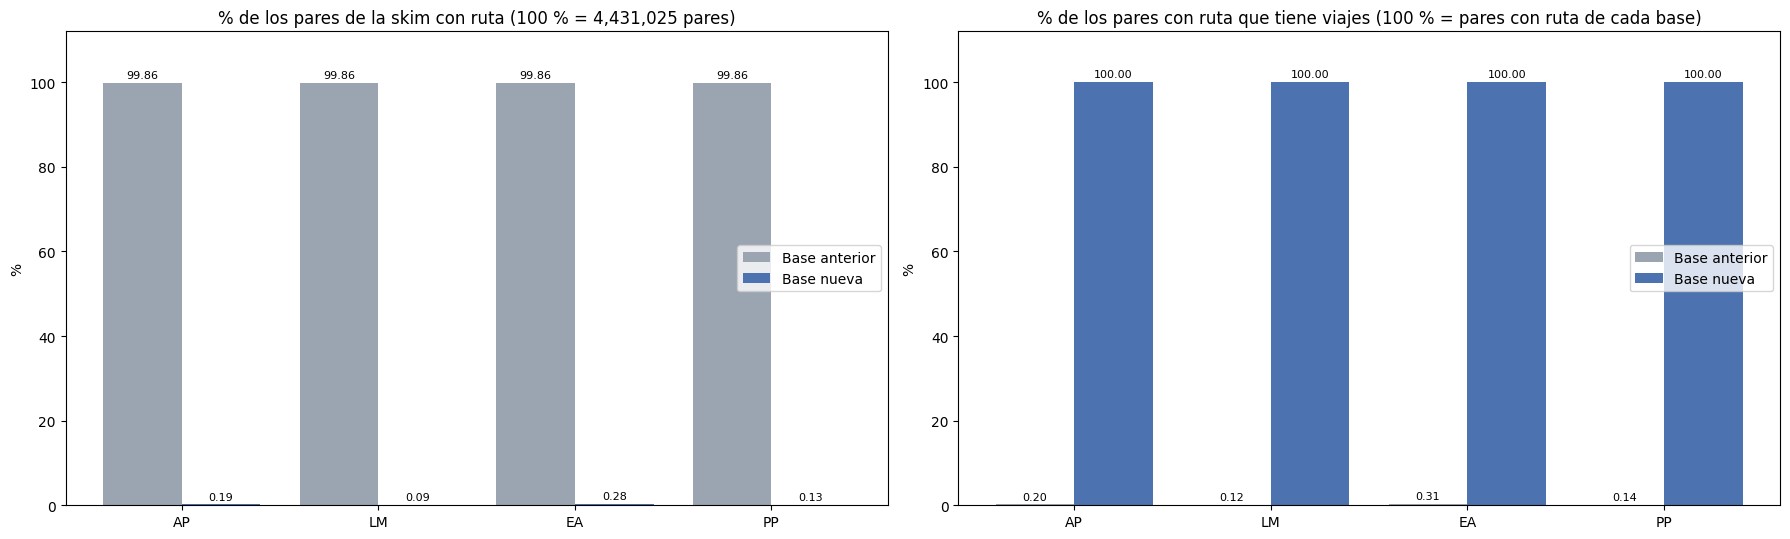

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
x = np.arange(len(PERIODOS))
ancho = 0.4
for k, base in enumerate(CARPETAS):
    t = cobertura.xs(base, level="Base").reindex(PERIODOS)
    barras = axes[0].bar(x + (k - 0.5) * ancho, t["% de la skim con ruta"], width=ancho, color=COLORES[base], label=base)
    axes[0].bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
    barras = axes[1].bar(x + (k - 0.5) * ancho, t["% de los pares con ruta que tiene viajes"], width=ancho,
                         color=COLORES[base], label=base)
    axes[1].bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
n_pares = int(cobertura["Pares de la skim"].iloc[0])
axes[0].set_title(f"% de los pares de la skim con ruta (100 % = {n_pares:,} pares)")
axes[1].set_title("% de los pares con ruta que tiene viajes (100 % = pares con ruta de cada base)")
for ax in axes:
    ax.set_xticks(x, PERIODOS)
    ax.set_ylabel("%")
    ax.set_ylim(0, 112)
    ax.legend()
plt.tight_layout()
plt.show()

- La base anterior tenía ruta en casi todos los pares de la skim; la base nueva solo en los pares con viajes (0.09 a 0.28 % de la skim).
- En la base nueva todos los pares con ruta tienen viajes. En la anterior, solo de 0.1 a 0.3 % de los pares con ruta tenía viajes.
- Solo de 0.12 a 0.31 % de todos los pares de la skim tiene viajes (sin contar intrazonales), en las dos bases porque la demanda es la misma.
- En la base nueva hay pares con viajes sin ruta: de 491 (AP) a 1,617 (EA) pares, con 1,116 a 2,669 viajes por periodo (menos de 1.6 % de los viajes).

### Viajes que existen en la demanda pero en la skim nueva salen sin ruta (999999)
Pares de zonas distintas con viajes en la demanda y TTC o DIST igual a 999999 en la base nueva. Como referencia se agrega el TTC y DIST que tenían en la base anterior.

In [9]:
nueva, anterior = CARPETAS["Base nueva"], CARPETAS["Base anterior"]
tablas_sin_ruta = []
for p in PERIODOS:
    demanda = cargar_demanda(p)
    o, d = demanda["Origin"].to_numpy(), demanda["Destination"].to_numpy()
    ttc_n, dist_n = leer_skim(nueva, "TTC", p)[o, d], leer_skim(nueva, "DIST", p)[o, d]
    sin_ruta = (ttc_n >= SIN_RUTA) | (dist_n >= SIN_RUTA)
    t = demanda[sin_ruta].copy()
    t["TTC base nueva"], t["DIST base nueva"] = ttc_n[sin_ruta], dist_n[sin_ruta]
    t["TTC base anterior"] = leer_skim(anterior, "TTC", p)[o, d][sin_ruta]
    t["DIST base anterior"] = leer_skim(anterior, "DIST", p)[o, d][sin_ruta]
    tablas_sin_ruta.append(t.assign(Periodo=p))

viajes_sin_ruta = pd.concat(tablas_sin_ruta, ignore_index=True).rename(
    columns={"Origen_ageb": "Zona_origen", "Destino_ageb": "Zona_destino", "Trips": "Viajes"})
viajes_sin_ruta["Mun_origen"] = viajes_sin_ruta["Zona_origen"].map(municipio)
viajes_sin_ruta["Mun_destino"] = viajes_sin_ruta["Zona_destino"].map(municipio)
viajes_sin_ruta = viajes_sin_ruta[
    ["Periodo", "Zona_origen", "Mun_origen", "Zona_destino", "Mun_destino", "Viajes"] + MODOS
    + ["TTC base nueva", "DIST base nueva", "TTC base anterior", "DIST base anterior"]
].sort_values(["Periodo", "Viajes"], key=lambda c: c.map(PERIODOS.index) if c.name == "Periodo" else -c)

ruta = os.path.join(R_TABLAS, "viajes_sin_ruta_filtro_2.csv")
viajes_sin_ruta.to_csv(ruta, index=False)
print("Guardado en", ruta)

# Resumen por periodo y tipo de vehículo
resumen_sin_ruta = viajes_sin_ruta.groupby("Periodo").agg(
    Pares=("Viajes", "size"), Viajes=("Viajes", "sum"),
    **{f"Viajes {NOMBRES_MODO[m]}": (m, "sum") for m in MODOS}).reindex(PERIODOS)
totales_modo = {p: cargar_demanda(p)[["Trips"] + MODOS].sum() for p in PERIODOS}
resumen_sin_ruta["% de los viajes del periodo"] = [
    resumen_sin_ruta.loc[p, "Viajes"] / totales_modo[p]["Trips"] * 100 for p in PERIODOS]
for m in MODOS:
    resumen_sin_ruta[f"% de {NOMBRES_MODO[m].lower()}"] = [
        resumen_sin_ruta.loc[p, f"Viajes {NOMBRES_MODO[m]}"] / totales_modo[p][m] * 100 for p in PERIODOS]
display(resumen_sin_ruta.round(2))

# Zonas que más se repiten (como origen o destino) en los pares sin ruta
extremos = pd.concat([
    viajes_sin_ruta[["Periodo", "Zona_origen", "Viajes"]].rename(columns={"Zona_origen": "Zona"}),
    viajes_sin_ruta[["Periodo", "Zona_destino", "Viajes"]].rename(columns={"Zona_destino": "Zona"}),
])
zonas_sin_ruta = extremos.groupby("Zona").agg(Pares=("Viajes", "size"), Viajes=("Viajes", "sum"))
zonas_sin_ruta.insert(0, "Municipio", zonas_sin_ruta.index.map(municipio))
print("15 zonas que más aparecen en pares con viajes sin ruta (4 periodos, como origen o destino)")
display(zonas_sin_ruta.sort_values("Viajes", ascending=False).head(15).round(1))

print("20 pares sin ruta con más viajes")
viajes_sin_ruta.sort_values("Viajes", ascending=False).head(20).round(2)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\tablas\viajes_sin_ruta_filtro_2.csv


,Pares,Viajes,Viajes Autos (VP),Viajes Carga pesada,Viajes Carga ligera,% de los viajes del periodo,% de autos (vp),% de carga pesada,% de carga ligera
Periodo,,,,,,,,,
AP,491,1116.25,0.0,484.80,631.45,0.32,0.0,97.45,97.50
LM,1084,2668.70,0.0,1189.45,1479.26,1.61,0.0,97.44,97.50
EA,1617,2437.49,0.0,1105.24,1332.25,0.85,0.0,94.84,95.59
PP,552,1340.78,0.0,618.61,722.17,0.48,0.0,94.60,96.59


15 zonas que más aparecen en pares con viajes sin ruta (4 periodos, como origen o destino)


,Municipio,Pares,Viajes
Zona,,,
10004,Acceso_Zapotlanejo_Cuota,726,2118.0
10001,Acceso_Vallarta,616,1756.3
10005,Acceso_Chapala,486,1389.9
10006,Acceso_Lopez_Mateos,596,1327.3
10007,Acceso_Zapotlanejo_Libre,276,487.9
412,Guadalajara,61,427.6
5903,Tlajomulco de Zúñiga,112,268.7
214,Guadalajara,60,224.6
8506,Zapopan,105,213.6


20 pares sin ruta con más viajes


,Periodo,Zona_origen,Mun_origen,Zona_destino,Mun_destino,Viajes,VP,HEAVY_FREIGHT,LIGHT_FREIGHT,TTC base nueva,DIST base nueva,TTC base anterior,DIST base anterior
3120,EA,10006,Acceso_Lopez_Mateos,10004,Acceso_Zapotlanejo_Cuota,49.11,0.0,39.63,9.49,999999.0,999999.0,56.63,101.30
1475,LM,10005,Acceso_Chapala,10004,Acceso_Zapotlanejo_Cuota,45.71,0.0,28.54,17.17,999999.0,999999.0,37.89,80.86
406,AP,10004,Acceso_Zapotlanejo_Cuota,10001,Acceso_Vallarta,45.14,0.0,25.88,19.26,999999.0,999999.0,82.89,94.83
1247,LM,10001,Acceso_Vallarta,10004,Acceso_Zapotlanejo_Cuota,43.18,0.0,31.65,11.54,999999.0,999999.0,74.44,109.69
2688,EA,10001,Acceso_Vallarta,10005,Acceso_Chapala,40.74,0.0,16.75,23.99,999999.0,999999.0,82.90,97.00
1403,LM,10004,Acceso_Zapotlanejo_Cuota,10001,Acceso_Vallarta,40.18,0.0,25.47,14.71,999999.0,999999.0,59.21,94.87
1538,LM,10006,Acceso_Lopez_Mateos,10004,Acceso_Zapotlanejo_Cuota,39.20,0.0,23.21,16.00,999999.0,999999.0,56.21,101.30
2912,EA,10004,Acceso_Zapotlanejo_Cuota,10001,Acceso_Vallarta,35.29,0.0,26.08,9.21,999999.0,999999.0,60.35,94.84
3726,PP,10006,Acceso_Lopez_Mateos,10004,Acceso_Zapotlanejo_Cuota,33.72,0.0,27.05,6.67,999999.0,999999.0,67.41,101.30
1451,LM,10005,Acceso_Chapala,5903,Tlajomulco de Zúñiga,31.54,0.0,19.77,11.77,999999.0,999999.0,16.88,34.73


- **Todos los viajes sin ruta son de carga; ningún viaje de autos se queda sin ruta.** De 95 a 97 % de los viajes de carga pesada y ligera de cada periodo están en pares que valen 999999.
- Casi todos van hacia o desde los accesos carreteros (10004 Zapotlanejo cuota, 10001 Vallarta, 10005 Chapala, 10006 López Mateos y 10007 Zapotlanejo libre). En la base anterior esos pares sí tenían tiempo y distancia.
- Parece que la skim nueva solo se calculó para los pares con viajes de autos. Hay que pedir que también se calcule para los pares de carga.
- La lista completa está en `skim_matrices/resultados_filtro_2/tablas/viajes_sin_ruta_filtro_2.csv`.

In [10]:
def describe(x, w=None):
    """Estadísticos de x; con pesos w (viajes) el promedio y los percentiles son por viaje."""
    x = pd.Series(x).reset_index(drop=True)
    w = pd.Series(1.0, index=x.index) if w is None else pd.Series(w).reset_index(drop=True)
    m = x.notna() & (w > 0)
    x, w = x[m].to_numpy(), w[m].to_numpy()
    orden = np.argsort(x)
    x, w = x[orden], w[orden]
    acumulado = (np.cumsum(w) - w / 2) / w.sum()
    promedio = np.average(x, weights=w)
    fila = {"Pares": len(x), "Viajes": w.sum(), "Promedio": promedio,
            "Desv. est.": np.sqrt(np.average((x - promedio) ** 2, weights=w)), "Mínimo": x.min()}
    for q in PERCENTILES:
        fila["Mediana" if q == 50 else f"P{q}"] = np.interp(q / 100, acumulado, x)
    fila["Máximo"] = x.max()
    return fila


def tabla_describe(tablas, columna, peso=None):
    """tablas: {(base, periodo): DataFrame}. Una fila por periodo y base."""
    filas = []
    for p in PERIODOS:
        for base in CARPETAS:
            t = tablas[(base, p)]
            fila = describe(t[columna], None if peso is None else t[peso])
            filas.append({"Periodo": p, "Base": base, **fila})
    t = pd.DataFrame(filas).set_index(["Periodo", "Base"])
    if peso is None:
        t = t.drop(columns="Viajes")
    return t.round(2)


def histograma(ax, series, variable, conteo):
    """series: {base: (valores, pesos)}. Barras lado a lado con el % de cada intervalo."""
    _, bins, labels, _ = VARIABLES[variable]
    ancho = 0.8 / len(series)
    for k, (base, (x, w)) in enumerate(series.items()):
        intervalo = pd.cut(np.asarray(x), bins=bins, labels=labels, right=False)
        suma = pd.Series(np.asarray(w, dtype=float)).groupby(intervalo, observed=False).sum()
        pct = suma / suma.sum() * 100
        barras = ax.bar(np.arange(len(labels)) + (k - (len(series) - 1) / 2) * ancho, pct, width=ancho,
                        color=COLORES[base], label=f"{base} (100 % = {suma.sum():,.0f} {conteo})")
        ax.bar_label(barras, labels=[f"{v:.1f}" if v >= 0.05 else "" for v in pct], fontsize=6, rotation=90, padding=2)
    ax.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=8)
    ax.set_xlabel(f"{VARIABLES[variable][0]} ({VARIABLES[variable][3]})")
    ax.set_ylabel(f"% de {conteo}")
    ax.margins(y=0.18)
    ax.legend(fontsize=8)


def figura_periodos(tablas, variable, conteo, titulo, peso=None):
    fig, axes = plt.subplots(len(PERIODOS), 1, figsize=(16, 4.5 * len(PERIODOS)))
    for ax, p in zip(axes, PERIODOS):
        series = {}
        for base in CARPETAS:
            t = tablas[(base, p)]
            series[base] = (t[variable], np.ones(len(t)) if peso is None else t[peso])
        histograma(ax, series, variable, conteo)
        ax.set_title(f"{p} - {VARIABLES[variable][0]} {titulo}")
    plt.tight_layout()
    plt.show()

## 1. Skims por pares
Cada par de zonas cuenta una vez.

In [11]:
for variable in VARIABLES:
    print(f"{VARIABLES[variable][0]} ({VARIABLES[variable][3]}) por par")
    display(tabla_describe(skims, variable))

Tiempo (min) por par


Pares  Promedio  Desv. est.  Mínimo    P5   P10    P25  \
Periodo Base                                                                    
AP      Base anterior   7554     19.32       15.29    0.80  2.69  3.89   7.62   
        Base nueva      8405     24.60       19.84    1.39  5.21  6.80  11.47   
LM      Base anterior   3509     13.97       11.50    0.80  2.21  2.96   5.49   
        Base nueva      4209     16.81       11.69    1.63  4.24  5.34   8.20   
EA      Base anterior  10891     16.10       12.41    0.56  2.55  3.49   6.59   
        Base nueva     12264     19.66       12.55    1.59  4.99  6.35  10.03   
PP      Base anterior   4969     17.61       14.49    0.56  2.58  3.57   6.89   
        Base nueva      5663     21.17       14.47    1.63  4.80  6.38  10.18   

                       Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                        
AP      Base anterior    15.33  26.71  40.57  50.08  69.21  130.48  
        Base nueva       20.24  32.47  46.43  55.82  82.43  222.64  
LM      Base anterior    10.51  19.20  30.30  36.68  51.20   79.15  
        Base nueva       13.71  22.19  32.47  39.43  56.15  109.98  
EA      Base anterior    12.95  22.14  33.54  41.01  55.71   92.16  
        Base nueva       16.88  26.23  37.18  43.80  59.47   97.44  
PP      Base anterior    13.77  23.99  37.02  45.17  67.16  133.87  
        Base nueva       17.93  28.07  40.58  48.95  70.34  105.40

Distancia (km) por par


Pares  Promedio  Desv. est.  Mínimo    P5   P10   P25  \
Periodo Base                                                                   
AP      Base anterior   7554     13.72       11.67    0.72  2.34  3.06  5.55   
        Base nueva      8405     13.17       11.78    0.39  1.48  2.23  4.74   
LM      Base anterior   3509     12.10       11.50    0.80  2.14  2.67  4.44   
        Base nueva      4209     11.15       11.25    0.37  1.14  1.65  3.42   
EA      Base anterior  10891     12.75       10.98    0.53  2.29  2.93  5.11   
        Base nueva     12264     12.21       10.87    0.37  1.44  2.16  4.35   
PP      Base anterior   4969     13.48       12.29    0.53  2.32  2.99  5.21   
        Base nueva      5663     12.69       11.62    0.38  1.37  2.12  4.33   

                       Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                        
AP      Base anterior    10.59  18.17  27.71  35.90  58.79  100.43  
        Base nueva       10.00  17.89  27.78  36.08  57.99   98.00  
LM      Base anterior     8.64  15.62  25.47  33.88  57.99  101.19  
        Base nueva        7.52  14.83  25.41  33.22  53.51   98.15  
EA      Base anterior     9.82  16.83  25.75  33.60  54.27  101.23  
        Base nueva        9.17  16.60  26.18  33.81  51.15   95.00  
PP      Base anterior    10.18  17.42  27.13  35.75  60.78  115.42  
        Base nueva        9.41  17.20  27.29  35.68  55.36   97.79

Velocidad (km/h) por par


Pares  Promedio  Desv. est.  Mínimo     P5    P10  \
Periodo Base                                                               
AP      Base anterior   7554     44.30       10.85   11.96  30.49  33.14   
        Base nueva      8405     29.70       10.58    5.84  14.83  17.38   
LM      Base anterior   3509     51.59       10.44   31.52  39.94  41.62   
        Base nueva      4209     33.92       13.48   10.05  14.49  17.14   
EA      Base anterior  10891     48.05       10.07   26.09  36.73  38.45   
        Base nueva     12264     32.91       11.58    9.92  15.52  18.61   
PP      Base anterior   4969     46.84       10.35   15.83  34.52  36.72   
        Base nueva      5663     31.87       11.30    6.81  14.90  17.80   

                         P25  Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                               
AP      Base anterior  37.61    42.26  48.67  58.07  65.36  81.21  108.35  
        Base nueva     22.35    28.39  35.29  43.27  48.91  61.79   90.97  
LM      Base anterior  44.48    48.88  56.00  65.25  72.87  89.80  108.88  
        Base nueva     23.81    32.82  41.67  53.18  59.33  69.27   93.14  
EA      Base anterior  41.44    45.59  51.78  60.68  69.05  83.16  109.42  
        Base nueva     24.88    32.15  39.25  48.44  53.84  64.31   92.81  
PP      Base anterior  40.20    44.53  51.28  59.70  67.80  79.90  106.52  
        Base nueva     23.85    31.07  38.57  46.36  51.80  63.85   81.46

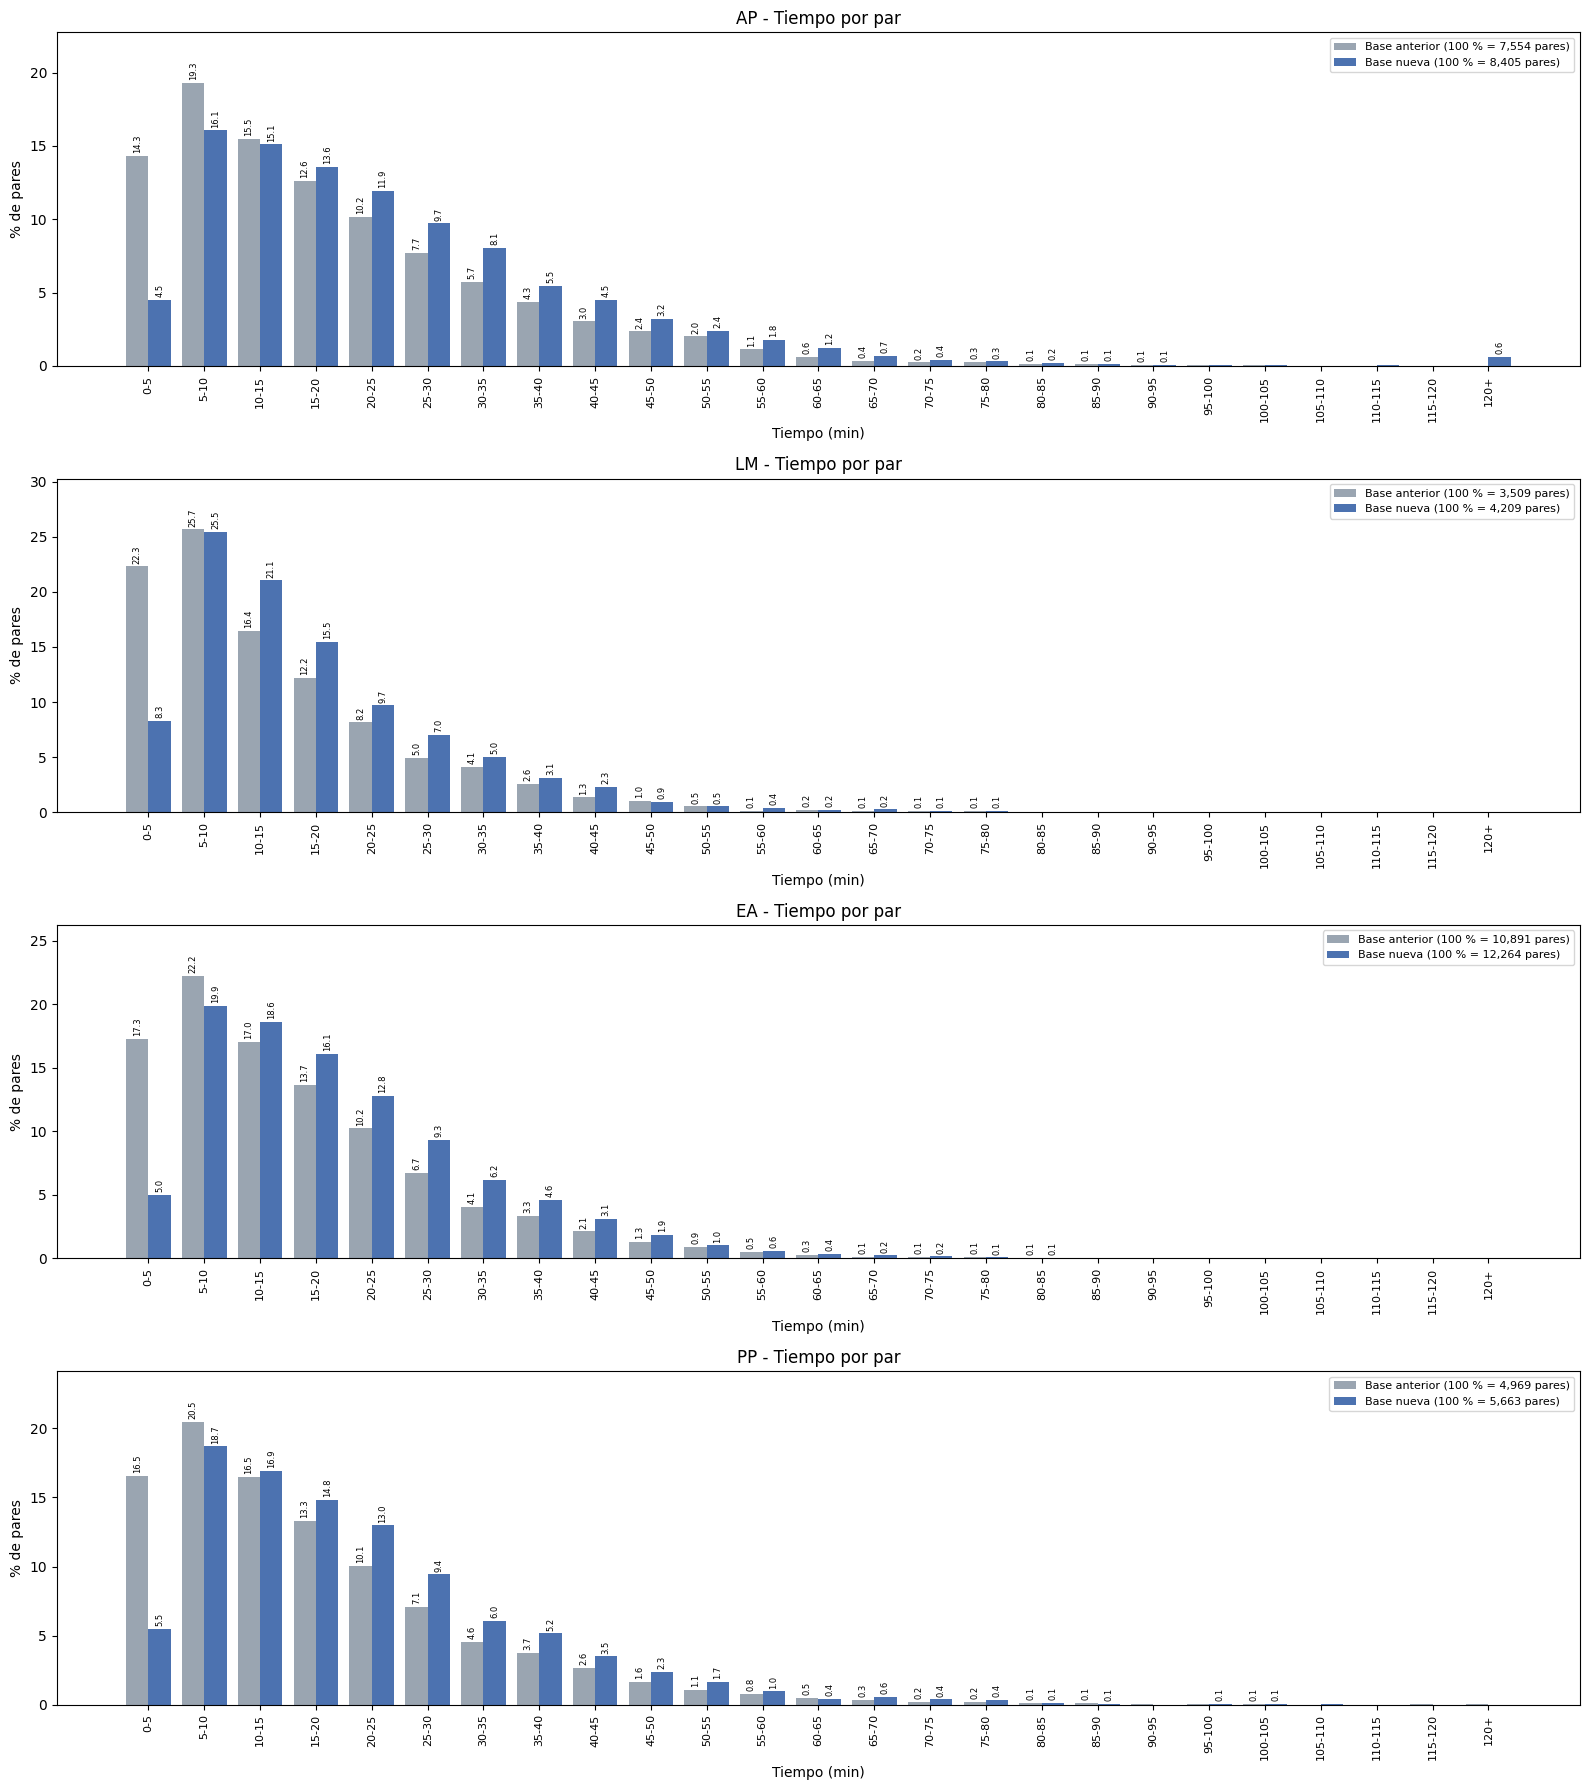

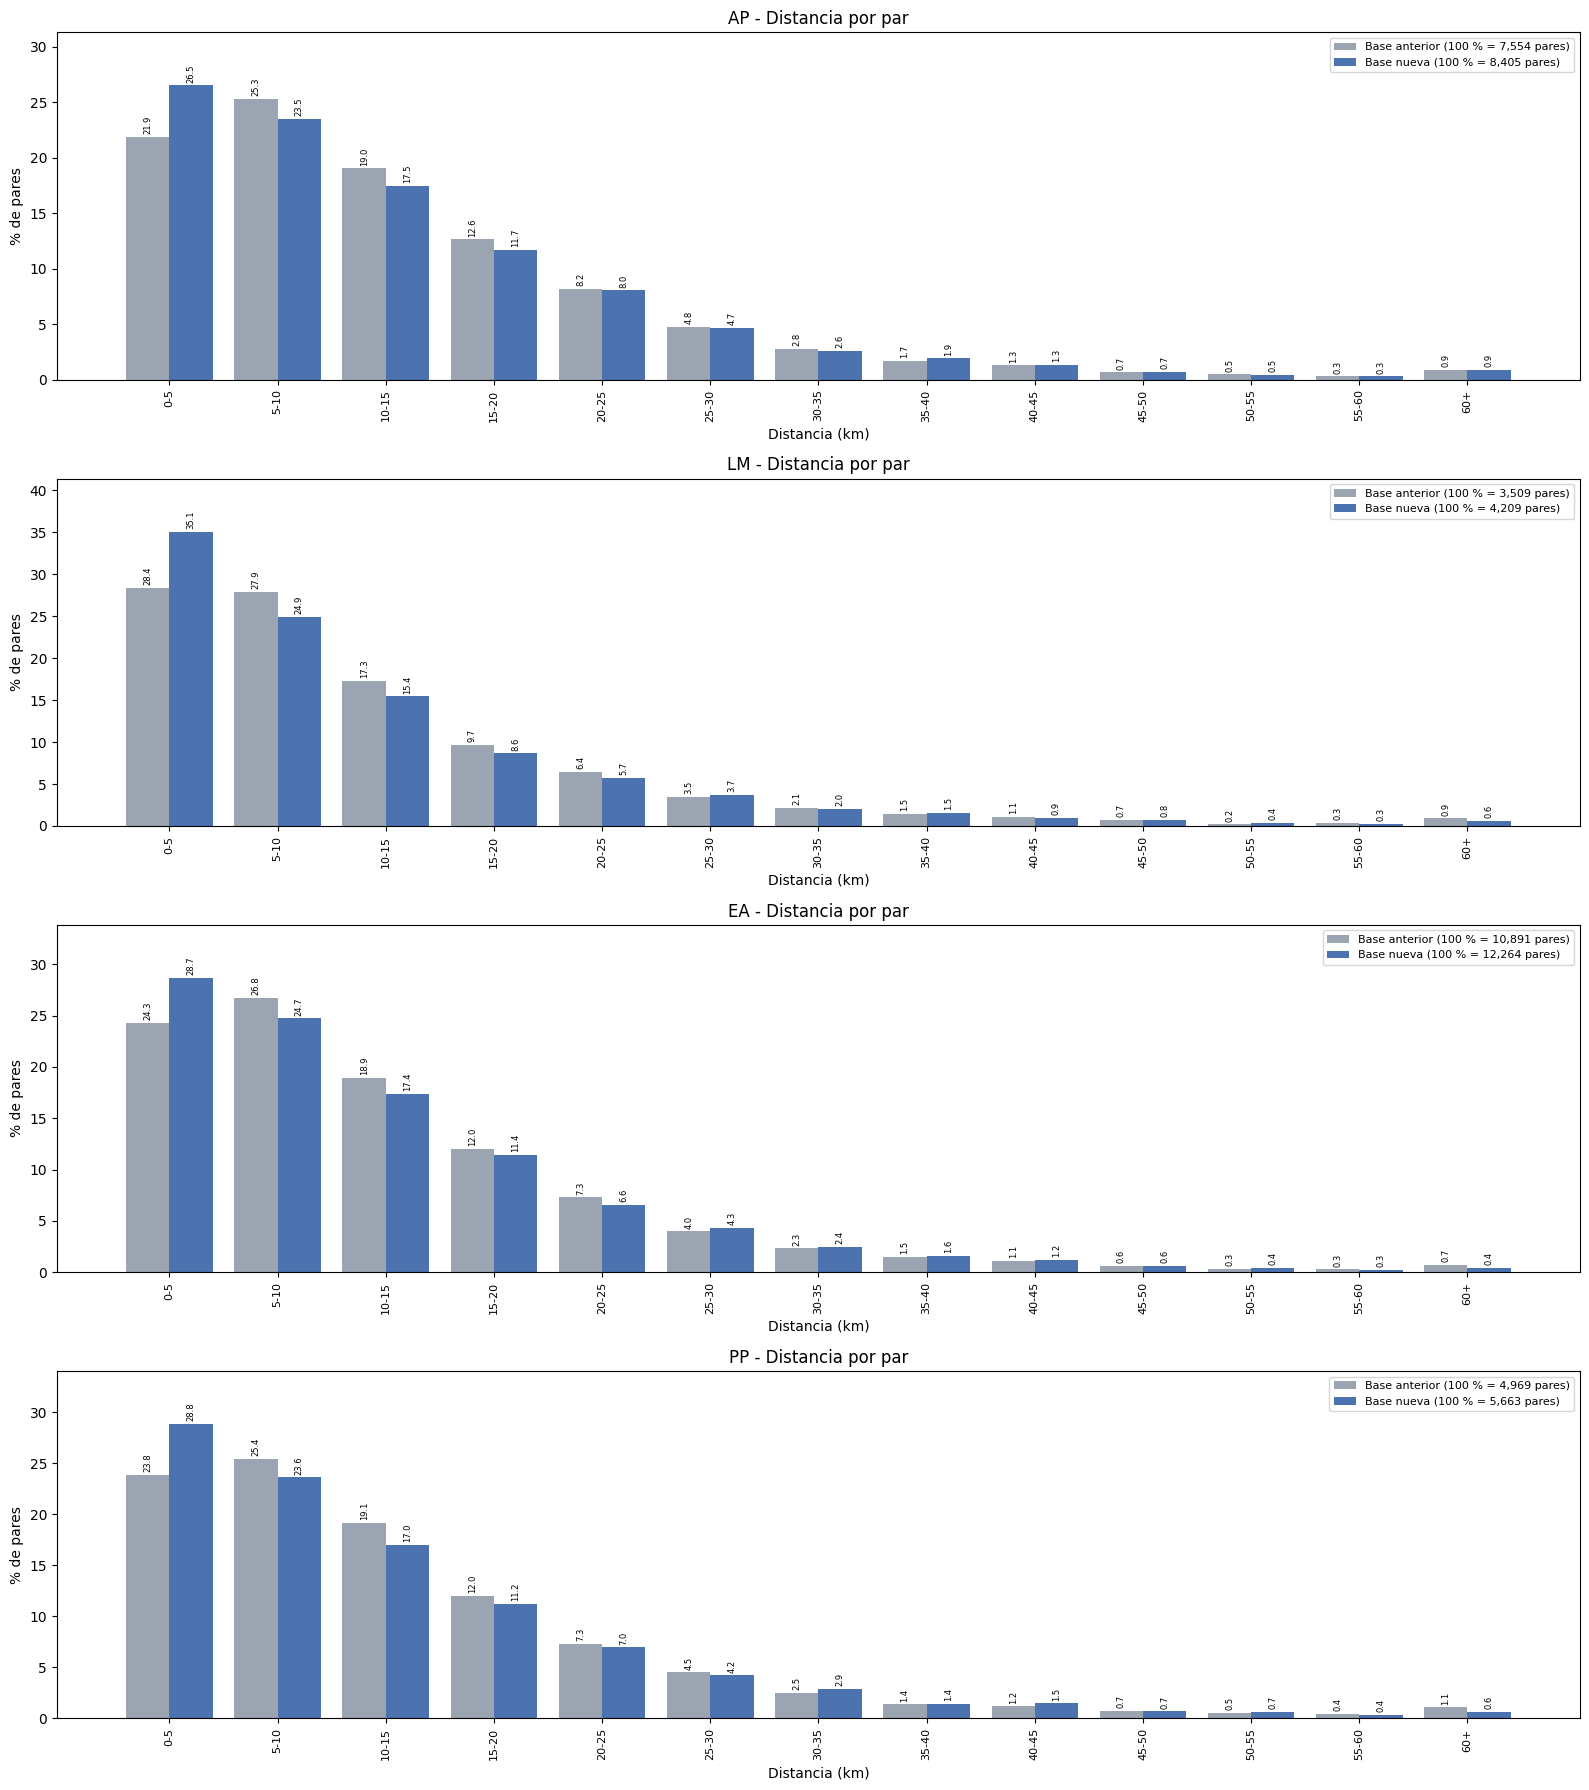

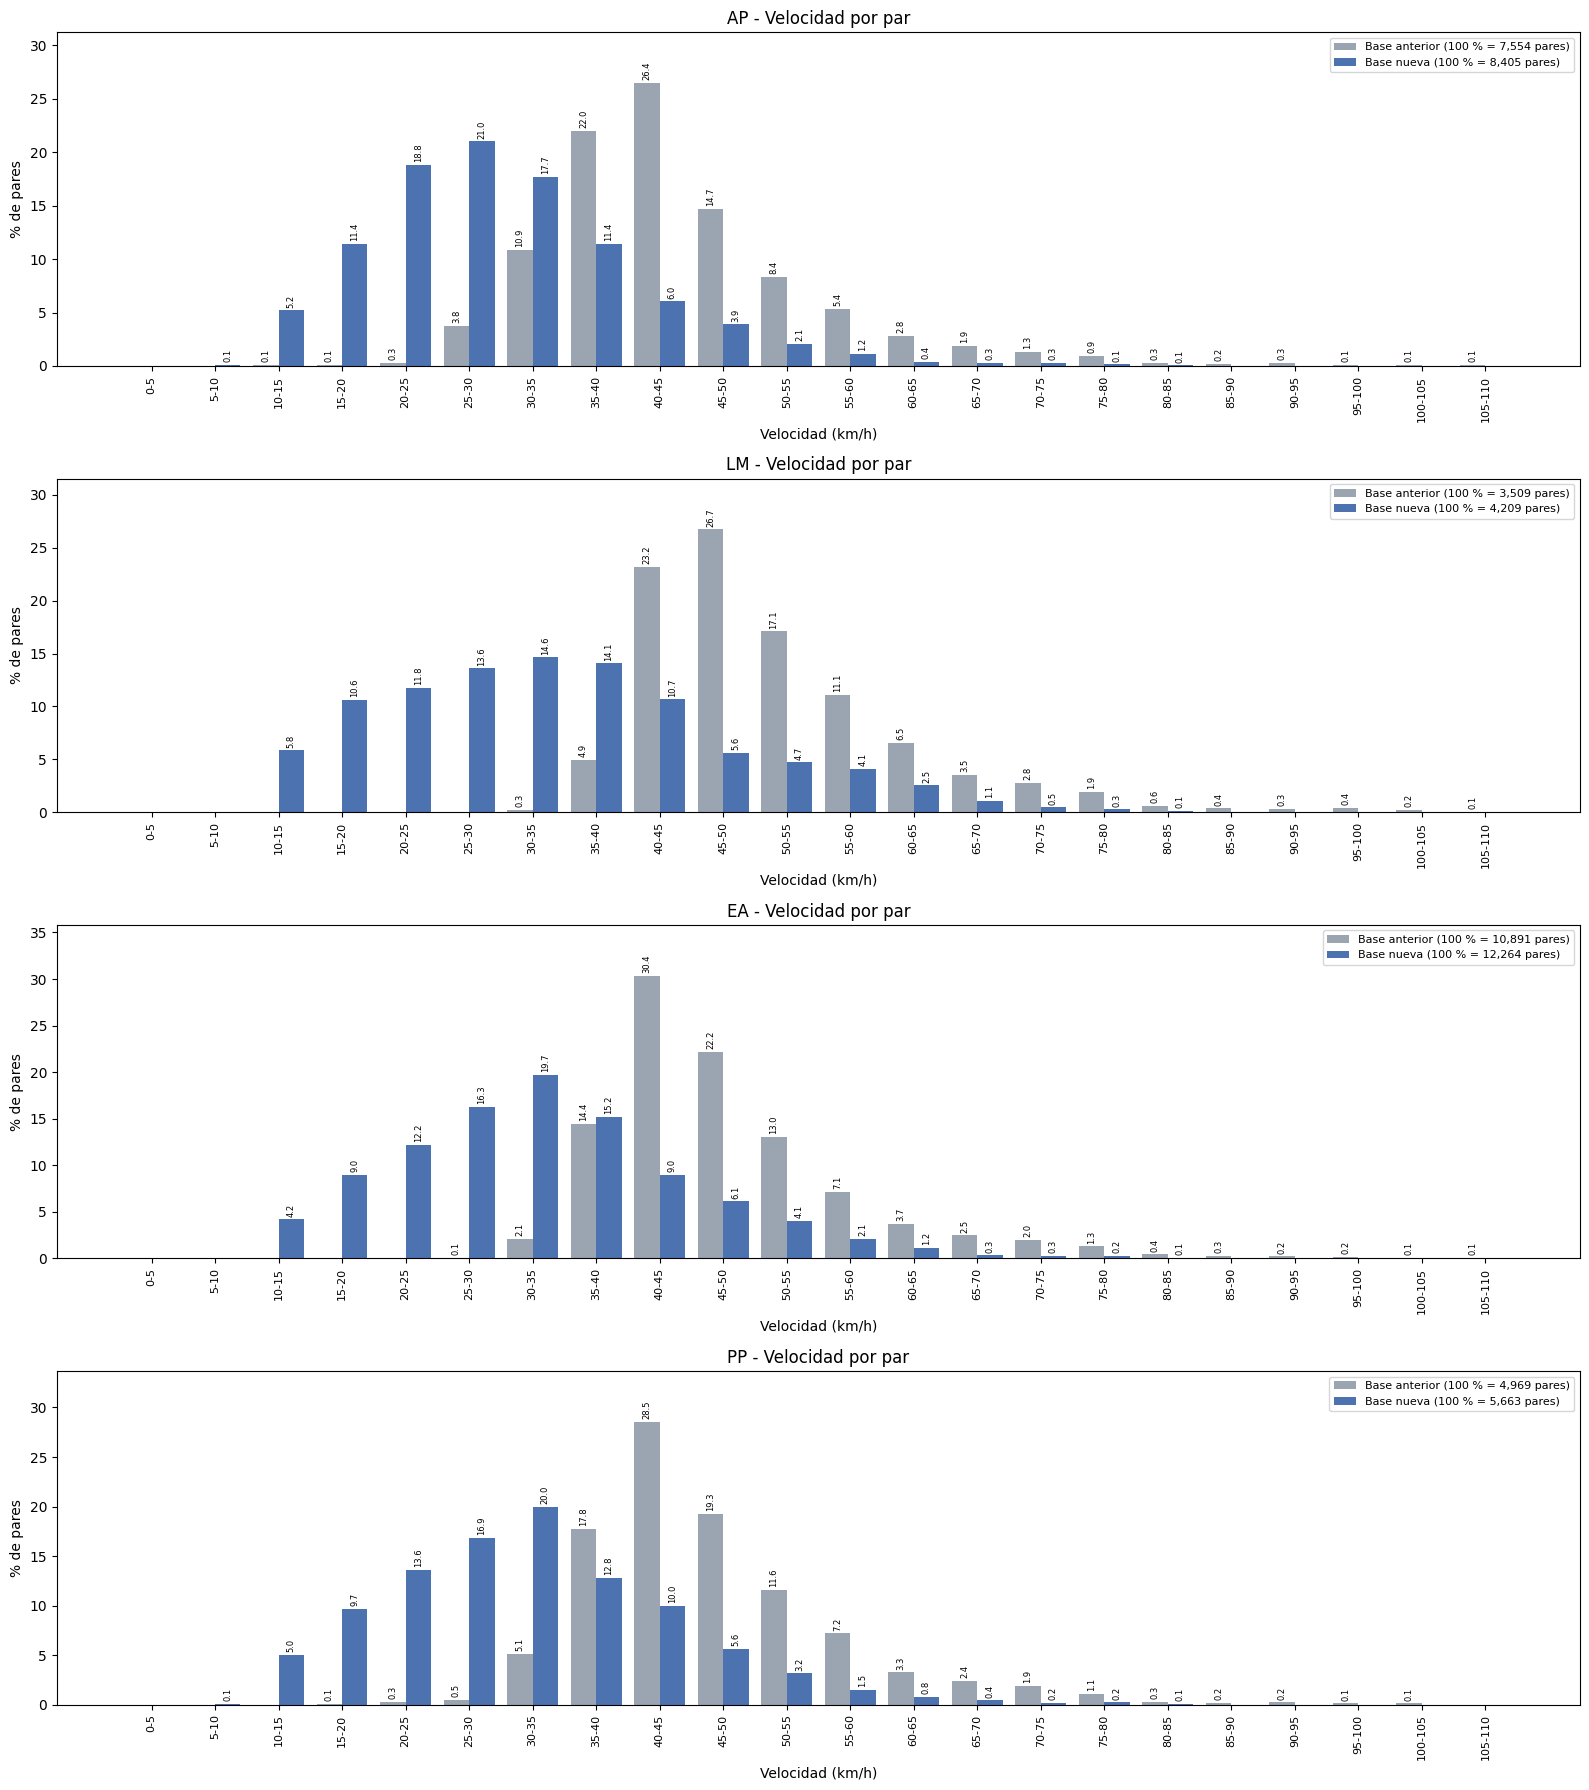

In [12]:
for variable in VARIABLES:
    figura_periodos(skims, variable, "pares", "por par")

## 2. Viajes (autos y carga juntos)
Cada par pesa según sus viajes; el promedio y los percentiles son por viaje.

In [13]:
for variable in VARIABLES:
    print(f"{VARIABLES[variable][0]} ({VARIABLES[variable][3]}) por viaje")
    display(tabla_describe(viajes, variable, peso="Trips"))

Tiempo (min) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo    P5  \
Periodo Base                                                                  
AP      Base anterior   8017  304316.66     17.19       15.10    0.80  2.30   
        Base nueva      8405  345836.67     21.91       20.17    1.39  4.52   
LM      Base anterior   4448  136155.63     12.37       10.98    0.80  2.14   
        Base nueva      4209  163192.74     14.28       10.06    1.63  3.84   
EA      Base anterior  12351  248907.92     14.03       11.86    0.56  2.21   
        Base nueva     12264  285530.59     16.86       11.48    1.59  4.46   
PP      Base anterior   5483  244115.71     16.05       14.76    0.56  2.34   
        Base nueva      5663  280682.82     18.96       14.18    1.63  4.44   

                        P10   P25  Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                                    
AP      Base anterior  3.18  5.98    12.68  23.61  37.79  48.52  70.64  130.48  
        Base nueva     5.86  9.15    16.63  28.13  44.01  55.08  83.04  222.64  
LM      Base anterior  2.68  4.47     8.83  16.63  27.14  35.04  50.68  109.17  
        Base nueva     4.79  7.17    11.31  18.32  28.42  34.82  50.41  109.98  
EA      Base anterior  2.90  5.26    10.50  19.31  30.10  38.68  54.04  118.23  
        Base nueva     5.56  8.29    13.78  22.27  33.16  40.15  54.68   97.44  
PP      Base anterior  3.24  5.82    11.79  21.24  34.49  43.80  71.75  133.87  
        Base nueva     5.58  8.79    15.08  24.52  38.19  47.24  70.24  105.40

Distancia (km) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo    P5  \
Periodo Base                                                                  
AP      Base anterior   8017  304316.66     11.80       11.11    0.72  2.03   
        Base nueva      8405  345836.67     10.91       10.70    0.39  1.21   
LM      Base anterior   4448  136155.63     10.66       11.60    0.80  2.04   
        Base nueva      4209  163192.74      8.96        9.48    0.37  0.98   
EA      Base anterior  12351  248907.92     10.91       10.66    0.53  2.03   
        Base nueva     12264  285530.59      9.85        9.45    0.37  1.21   
PP      Base anterior   5483  244115.71     12.03       12.62    0.53  2.14   
        Base nueva      5663  280682.82     10.74       10.68    0.38  1.18   

                        P10   P25  Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                                    
AP      Base anterior  2.59  4.30     8.64  15.46  24.27  31.44  58.80  116.64  
        Base nueva     1.79  3.44     7.73  14.81  23.73  30.86  53.36   98.00  
LM      Base anterior  2.47  3.73     6.81  12.85  22.48  31.71  60.77  121.22  
        Base nueva     1.40  2.75     5.93  11.55  20.44  27.94  45.50   98.15  
EA      Base anterior  2.56  4.06     7.73  13.99  22.43  29.27  56.81  123.97  
        Base nueva     1.74  3.24     6.92  13.23  21.84  28.14  46.72   95.00  
PP      Base anterior  2.69  4.30     8.48  14.92  24.45  33.53  69.79  123.75  
        Base nueva     1.74  3.49     7.53  14.19  23.46  31.76  54.60   97.79

Velocidad (km/h) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo     P5  \
Periodo Base                                                                   
AP      Base anterior   8017  304316.66     43.38        9.81   11.96  30.07   
        Base nueva      8405  345836.67     27.48        9.39    5.84  13.95   
LM      Base anterior   4448  136155.63     50.66        9.96   31.52  40.01   
        Base nueva      4209  163192.74     31.50       12.19   10.05  13.74   
EA      Base anterior  12351  248907.92     47.32        9.54   26.09  36.73   
        Base nueva     12264  285530.59     30.39       10.33    9.92  15.09   
PP      Base anterior   5483  244115.71     45.77        9.74   15.83  33.81   
        Base nueva      5663  280682.82     29.74       10.16    6.81  14.06   

                         P10    P25  Mediana    P75    P90    P95    P99  \
Periodo Base                                                               
AP      Base anterior  32.89  37.65    41.90  47.36  55.59  61.57  76.84   
        Base nueva     16.22  21.11    26.71  32.69  38.70  44.00  57.83   
LM      Base anterior  41.61  44.00    48.02  54.21  63.00  71.78  86.53   
        Base nueva     16.28  22.52    30.78  38.52  47.67  54.60  64.78   
EA      Base anterior  38.44  41.23    44.88  50.82  59.35  67.04  79.47   
        Base nueva     17.48  23.07    29.99  36.24  43.70  48.74  59.63   
PP      Base anterior  36.21  39.82    43.86  49.60  57.68  65.14  78.39   
        Base nueva     16.93  22.74    29.19  35.45  42.81  46.90  58.44   

                       Máximo  
Periodo Base                   
AP      Base anterior  109.75  
        Base nueva      90.97  
LM      Base anterior  109.85  
        Base nueva      93.14  
EA      Base anterior  109.69  
        Base nueva      92.81  
PP      Base anterior  109.85  
        Base nueva      81.46

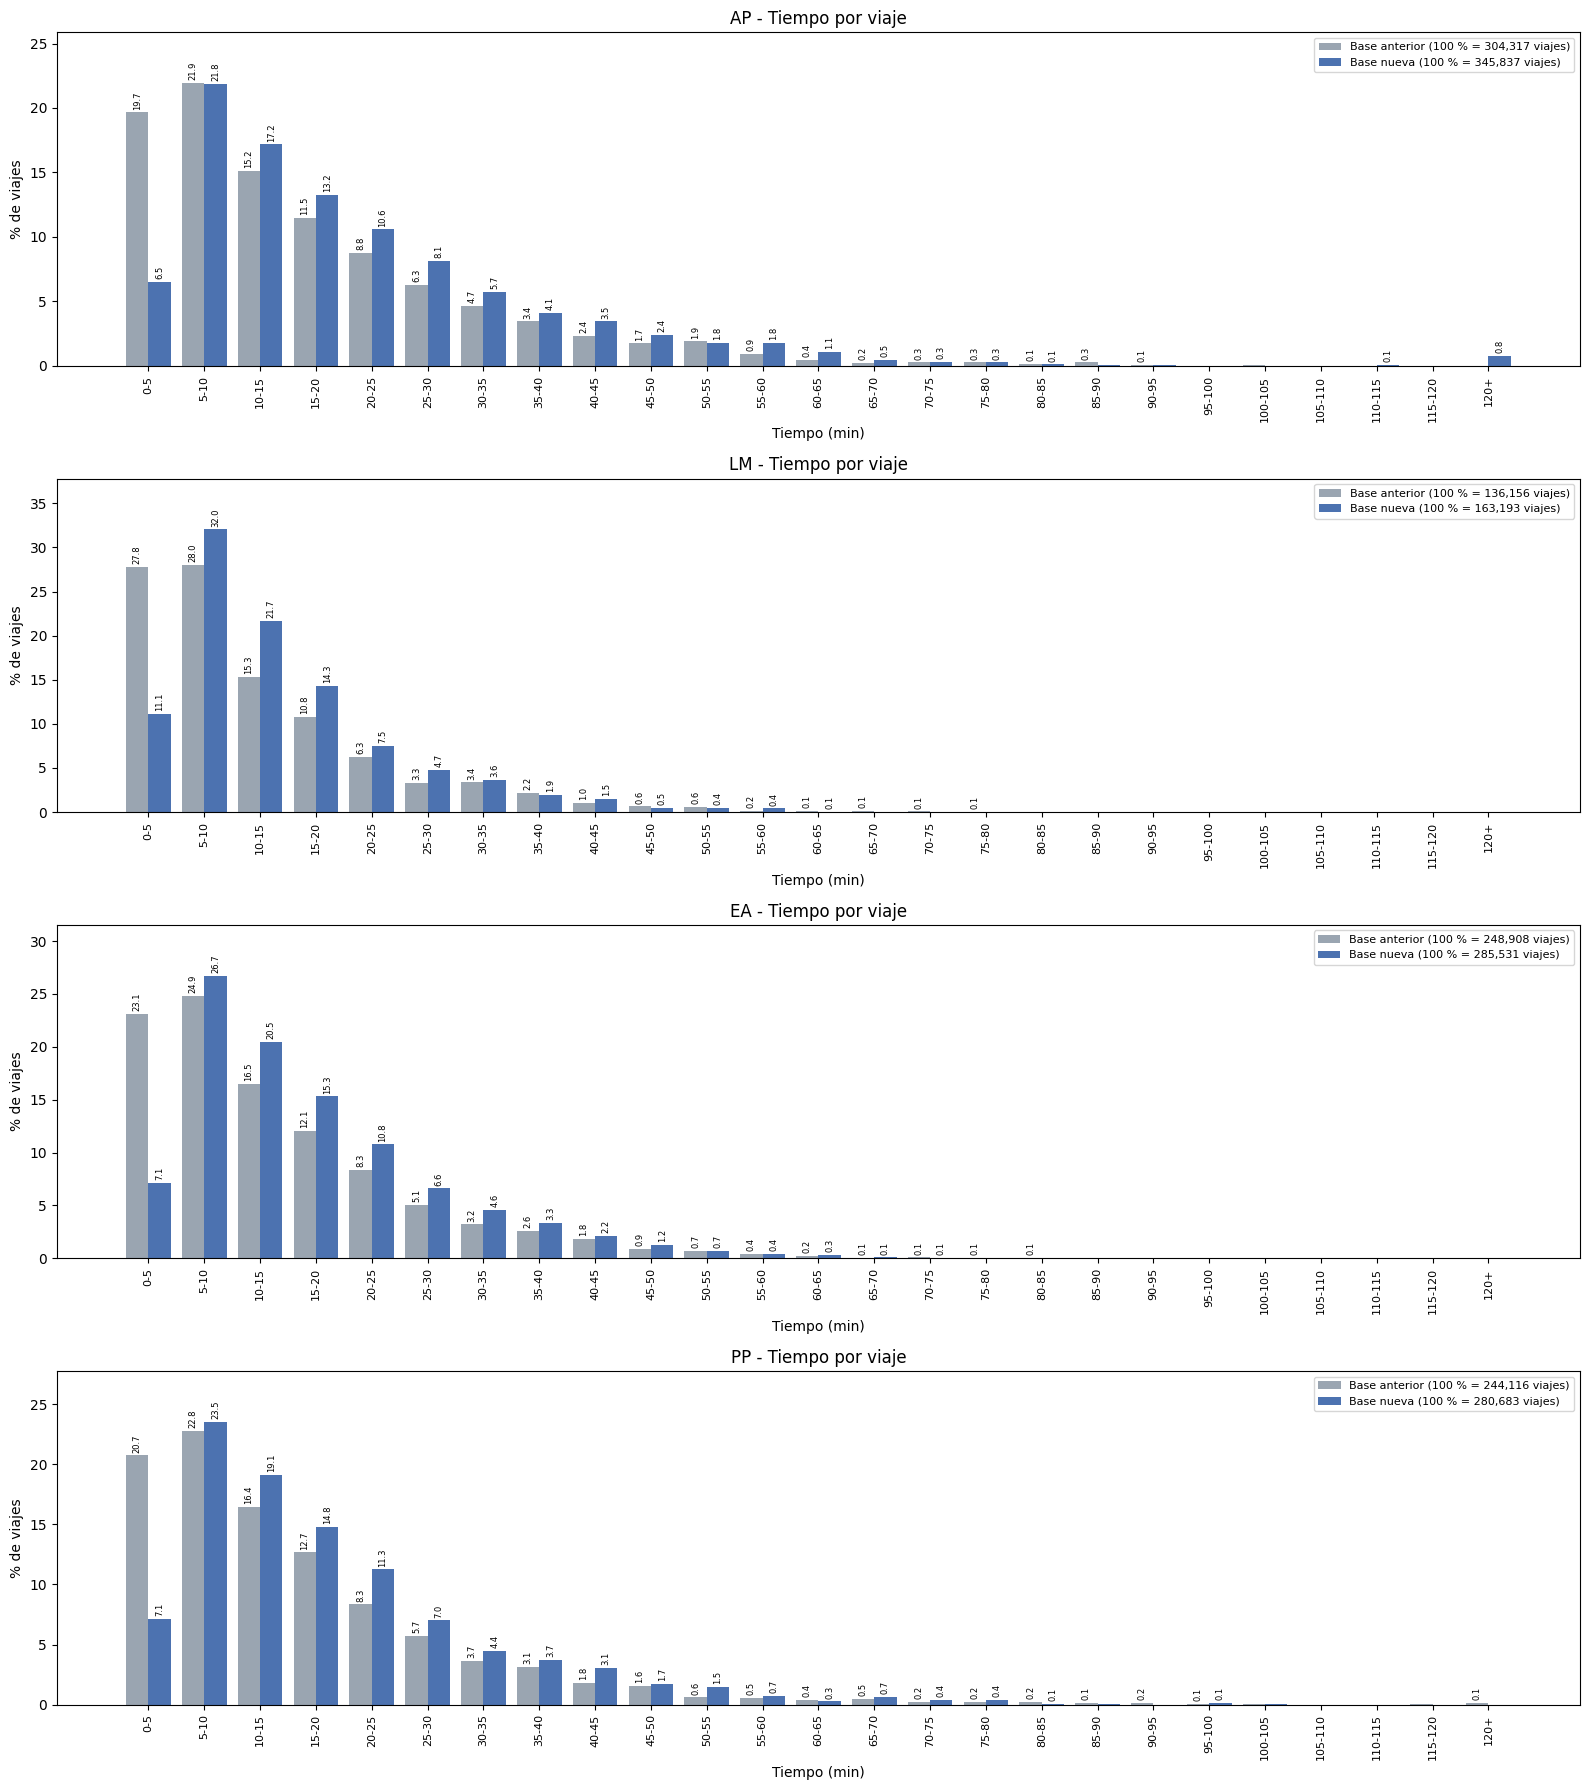

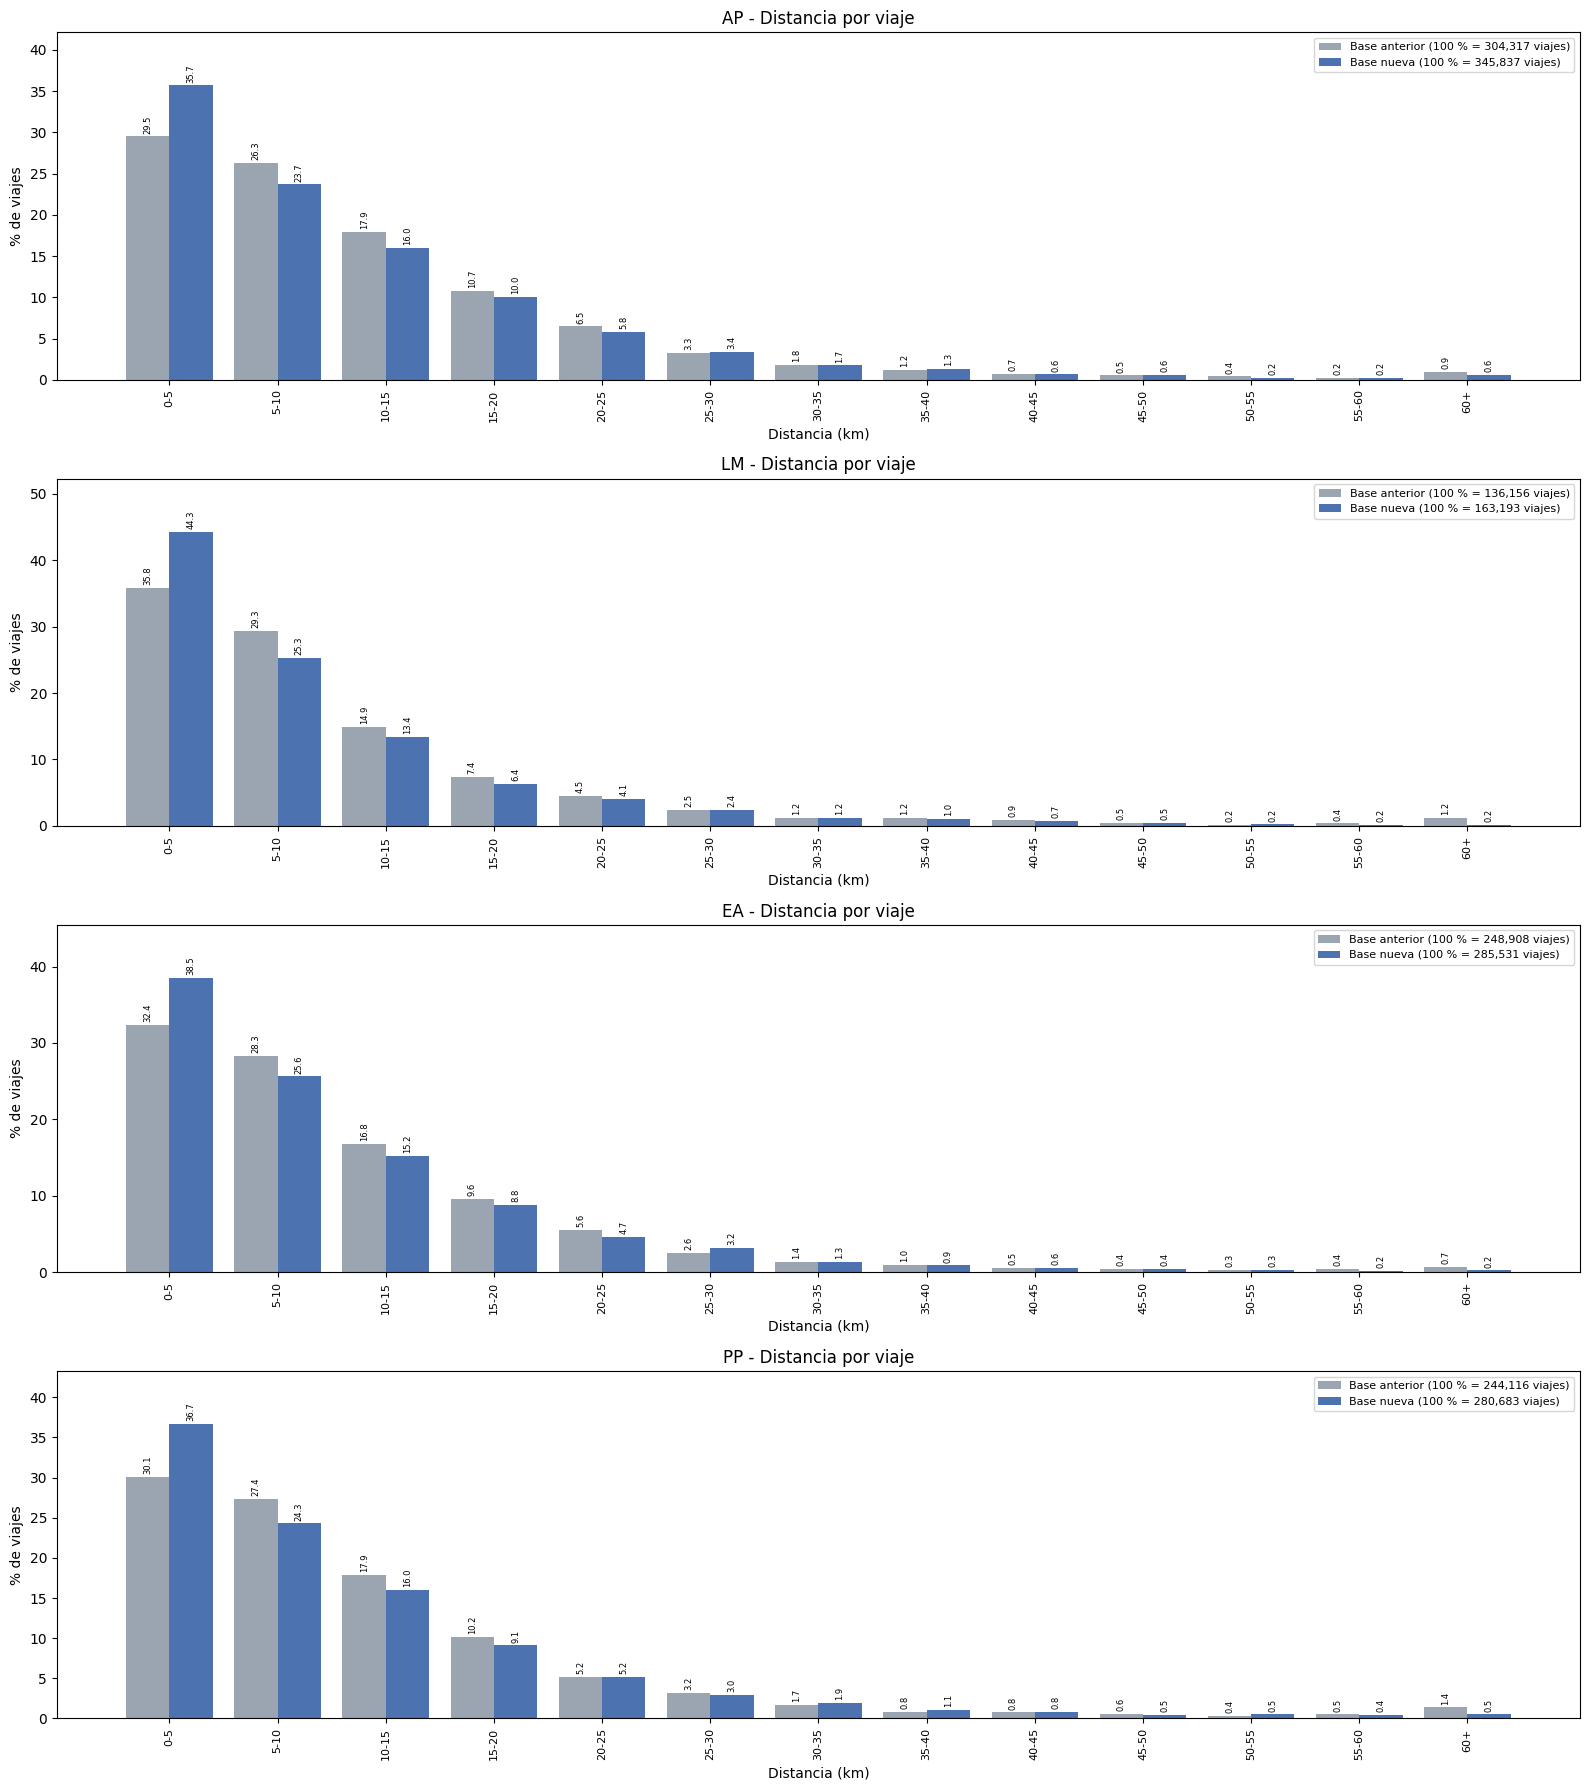

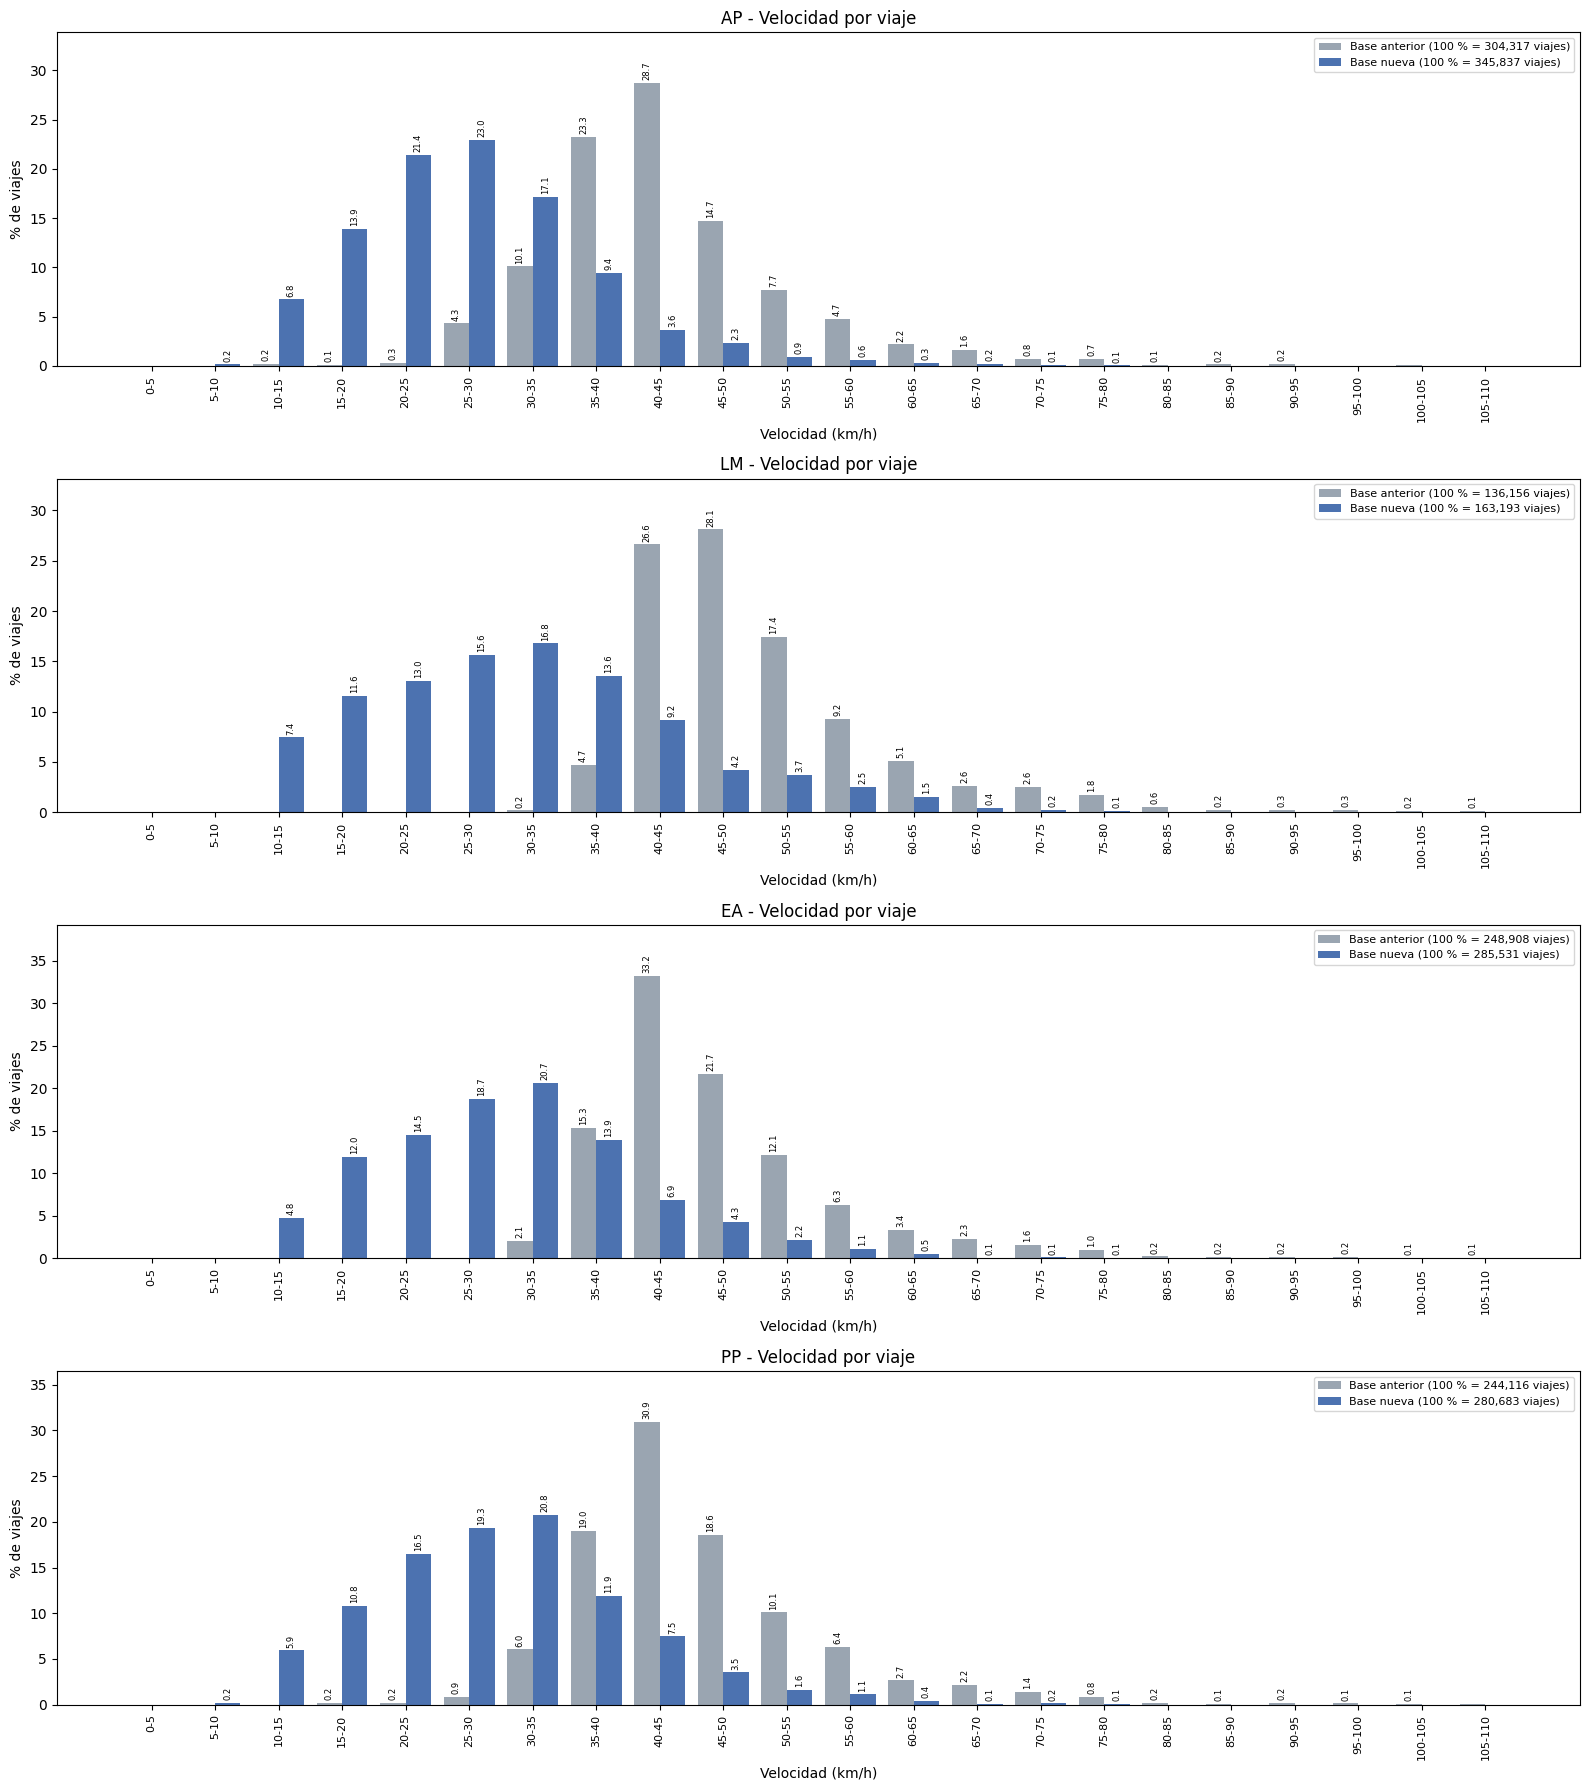

In [14]:
for variable in VARIABLES:
    figura_periodos(viajes, variable, "viajes", "por viaje", peso="Trips")

## 3. Viajes por tipo de vehículo
Autos (VP), carga pesada y carga ligera por separado.

In [15]:
for modo in MODOS:
    viajes_modo = {k: t[t[modo] > 0] for k, t in viajes.items()}
    for variable in VARIABLES:
        print(f"{NOMBRES_MODO[modo]}: {VARIABLES[variable][0]} ({VARIABLES[variable][3]}) por viaje")
        display(tabla_describe(viajes_modo, variable, peso=modo))

Autos (VP): Tiempo (min) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo    P5  \
Periodo Base                                                                  
AP      Base anterior   7554  303241.31     17.06       14.91    0.80  2.29   
        Base nueva      8405  345807.74     21.90       20.15    1.39  4.52   
LM      Base anterior   3509  133997.72     11.91       10.24    0.80  2.13   
        Base nueva      4209  163123.51     14.27       10.06    1.63  3.84   
EA      Base anterior  10891  246725.63     13.76       11.43    0.56  2.20   
        Base nueva     12264  285408.95     16.86       11.47    1.59  4.46   
PP      Base anterior   4969  242841.46     15.88       14.53    0.56  2.34   
        Base nueva      5663  280622.04     18.96       14.18    1.63  4.44   

                        P10   P25  Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                                    
AP      Base anterior  3.17  5.98    12.65  23.45  37.37  47.82  69.95  130.48  
        Base nueva     5.86  9.15    16.62  28.13  44.01  55.07  82.97  222.64  
LM      Base anterior  2.67  4.41     8.60  16.29  25.45  33.57  47.49   79.15  
        Base nueva     4.79  7.17    11.31  18.31  28.42  34.79  50.43  109.98  
EA      Base anterior  2.89  5.24    10.42  18.90  29.28  37.65  52.17   92.16  
        Base nueva     5.56  8.29    13.78  22.26  33.15  40.07  54.68   97.44  
PP      Base anterior  3.23  5.81    11.69  21.11  34.06  42.80  71.63  133.87  
        Base nueva     5.58  8.79    15.08  24.52  38.15  47.23  70.24  105.40

Autos (VP): Distancia (km) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo    P5  \
Periodo Base                                                                  
AP      Base anterior   7554  303241.31     11.63       10.67    0.72  2.03   
        Base nueva      8405  345807.74     10.91       10.70    0.39  1.21   
LM      Base anterior   3509  133997.72      9.95        9.80    0.80  2.03   
        Base nueva      4209  163123.51      8.95        9.46    0.37  0.98   
EA      Base anterior  10891  246725.63     10.52        9.57    0.53  2.02   
        Base nueva     12264  285408.95      9.84        9.42    0.37  1.21   
PP      Base anterior   4969  242841.46     11.80       12.15    0.53  2.13   
        Base nueva      5663  280622.04     10.73       10.67    0.38  1.18   

                        P10   P25  Mediana    P75    P90    P95    P99  Máximo  
Periodo Base                                                                    
AP      Base anterior  2.58  4.29     8.60  15.37  24.07  30.96  54.75  100.43  
        Base nueva     1.79  3.44     7.73  14.81  23.73  30.85  53.36   98.00  
LM      Base anterior  2.44  3.72     6.69  12.44  21.05  28.37  47.55  101.19  
        Base nueva     1.40  2.75     5.93  11.54  20.43  27.86  45.43   98.15  
EA      Base anterior  2.55  4.06     7.66  13.78  21.90  27.85  48.95  101.23  
        Base nueva     1.73  3.24     6.91  13.21  21.79  28.08  46.41   95.00  
PP      Base anterior  2.68  4.29     8.46  14.76  23.98  32.30  64.18  115.42  
        Base nueva     1.74  3.49     7.53  14.19  23.45  31.75  54.59   97.79

Autos (VP): Velocidad (km/h) por viaje


Pares     Viajes  Promedio  Desv. est.  Mínimo     P5  \
Periodo Base                                                                   
AP      Base anterior   7554  303241.31     43.29        9.64   11.96  30.05   
        Base nueva      8405  345807.74     27.48        9.39    5.84  13.95   
LM      Base anterior   3509  133997.72     50.20        9.09   31.52  40.01   
        Base nueva      4209  163123.51     31.49       12.18   10.05  13.74   
EA      Base anterior  10891  246725.63     47.08        9.08   26.09  36.72   
        Base nueva     12264  285408.95     30.38       10.32    9.92  15.09   
PP      Base anterior   4969  242841.46     45.65        9.52   15.83  33.80   
        Base nueva      5663  280622.04     29.73       10.15    6.81  14.06   

                         P10    P25  Mediana    P75    P90    P95    P99  \
Periodo Base                                                               
AP      Base anterior  32.89  37.64    41.87  47.26  55.36  61.30  75.75   
        Base nueva     16.22  21.11    26.71  32.69  38.70  43.99  57.83   
LM      Base anterior  41.56  43.97    47.86  53.82  61.57  69.50  79.47   
        Base nueva     16.28  22.52    30.78  38.49  47.67  54.58  64.75   
EA      Base anterior  38.43  41.19    44.83  50.65  58.76  65.80  77.43   
        Base nueva     17.48  23.07    29.99  36.22  43.69  48.71  59.60   
PP      Base anterior  36.19  39.81    43.78  49.41  57.40  64.41  77.33   
        Base nueva     16.93  22.74    29.18  35.45  42.81  46.88  58.42   

                       Máximo  
Periodo Base                   
AP      Base anterior  108.35  
        Base nueva      90.97  
LM      Base anterior  108.88  
        Base nueva      93.14  
EA      Base anterior  109.42  
        Base nueva      92.81  
PP      Base anterior  106.52  
        Base nueva      81.46

... (8 outputs left out)

Carga ligera: Distancia (km) por viaje


Pares   Viajes  Promedio  Desv. est.  Mínimo     P5  \
Periodo Base                                                                 
AP      Base anterior    293   610.77     54.00       23.23    3.60  17.55   
        Base nueva         9    16.22     30.55       21.72    4.28   6.86   
LM      Base anterior    599  1219.82     50.54       23.48    1.88  10.64   
        Base nueva        14    37.97     23.14       15.52    3.32   5.09   
EA      Base anterior    972  1213.97     51.20       23.70    1.53  14.46   
        Base nueva        40    61.46     31.48       19.62    2.18   7.80   
PP      Base anterior    314   691.75     50.77       23.80    2.56  14.09   
        Base nueva         9    25.47     25.85       16.93    8.27   8.27   

                         P10    P25  Mediana    P75    P90    P95     P99  \
Periodo Base                                                                
AP      Base anterior  26.92  38.51    51.18  69.19  94.38  96.50  109.19   
        Base nueva     10.92  15.23    20.00  56.16  65.04  65.08   65.08   
LM      Base anterior  21.48  37.60    47.47  65.96  79.87  96.36  109.66   
        Base nueva      7.48  11.33    21.09  25.62  49.70  60.77   62.37   
EA      Base anterior  21.60  36.28    48.65  65.81  85.46  96.73  109.55   
        Base nueva      8.41  16.95    28.54  44.21  67.58  67.65   67.65   
PP      Base anterior  21.21  34.91    49.04  66.92  80.95  95.90  114.88   
        Base nueva      8.91  15.78    21.25  26.71  53.66  66.61   66.61   

                       Máximo  
Periodo Base                   
AP      Base anterior  116.64  
        Base nueva      65.08  
LM      Base anterior  115.81  
        Base nueva      62.37  
EA      Base anterior  115.78  
        Base nueva      67.65  
PP      Base anterior  123.75  
        Base nueva      66.61

Carga ligera: Velocidad (km/h) por viaje


Pares   Viajes  Promedio  Desv. est.  Mínimo     P5  \
Periodo Base                                                                 
AP      Base anterior    293   610.77     63.89       20.42   29.02  40.50   
        Base nueva         9    16.22     27.87       15.32    9.90   9.90   
LM      Base anterior    599  1219.82     76.68       17.25   34.79  46.52   
        Base nueva        14    37.97     47.56       18.76   10.89  13.96   
EA      Base anterior    972  1213.97     71.16       18.28   33.78  40.76   
        Base nueva        40    61.46     49.66       16.91   15.47  17.05   
PP      Base anterior    314   691.75     65.94       19.04   33.53  39.92   
        Base nueva         9    25.47     37.39       20.71   15.54  15.54   

                         P10    P25  Mediana    P75    P90     P95     P99  \
Periodo Base                                                                 
AP      Base anterior  42.28  47.32    56.12  81.83  94.07  100.88  109.57   
        Base nueva     11.27  16.29    21.99  39.29  50.77   51.35   51.53   
LM      Base anterior  50.00  64.12    78.27  89.17  98.17  104.47  108.30   
        Base nueva     16.25  42.32    53.61  59.35  66.68   79.29   81.10   
EA      Base anterior  47.47  57.65    70.39  83.48  96.09  104.39  108.92   
        Base nueva     19.53  39.90    54.30  59.38  72.06   74.45   74.45   
PP      Base anterior  43.09  51.15    62.14  79.16  94.67  102.42  107.88   
        Base nueva     15.94  20.31    32.57  53.10  70.05   79.59   79.59   

                       Máximo  
Periodo Base                   
AP      Base anterior  109.75  
        Base nueva      51.53  
LM      Base anterior  109.30  
        Base nueva      81.10  
EA      Base anterior  109.67  
        Base nueva      74.45  
PP      Base anterior  109.39  
        Base nueva      79.59

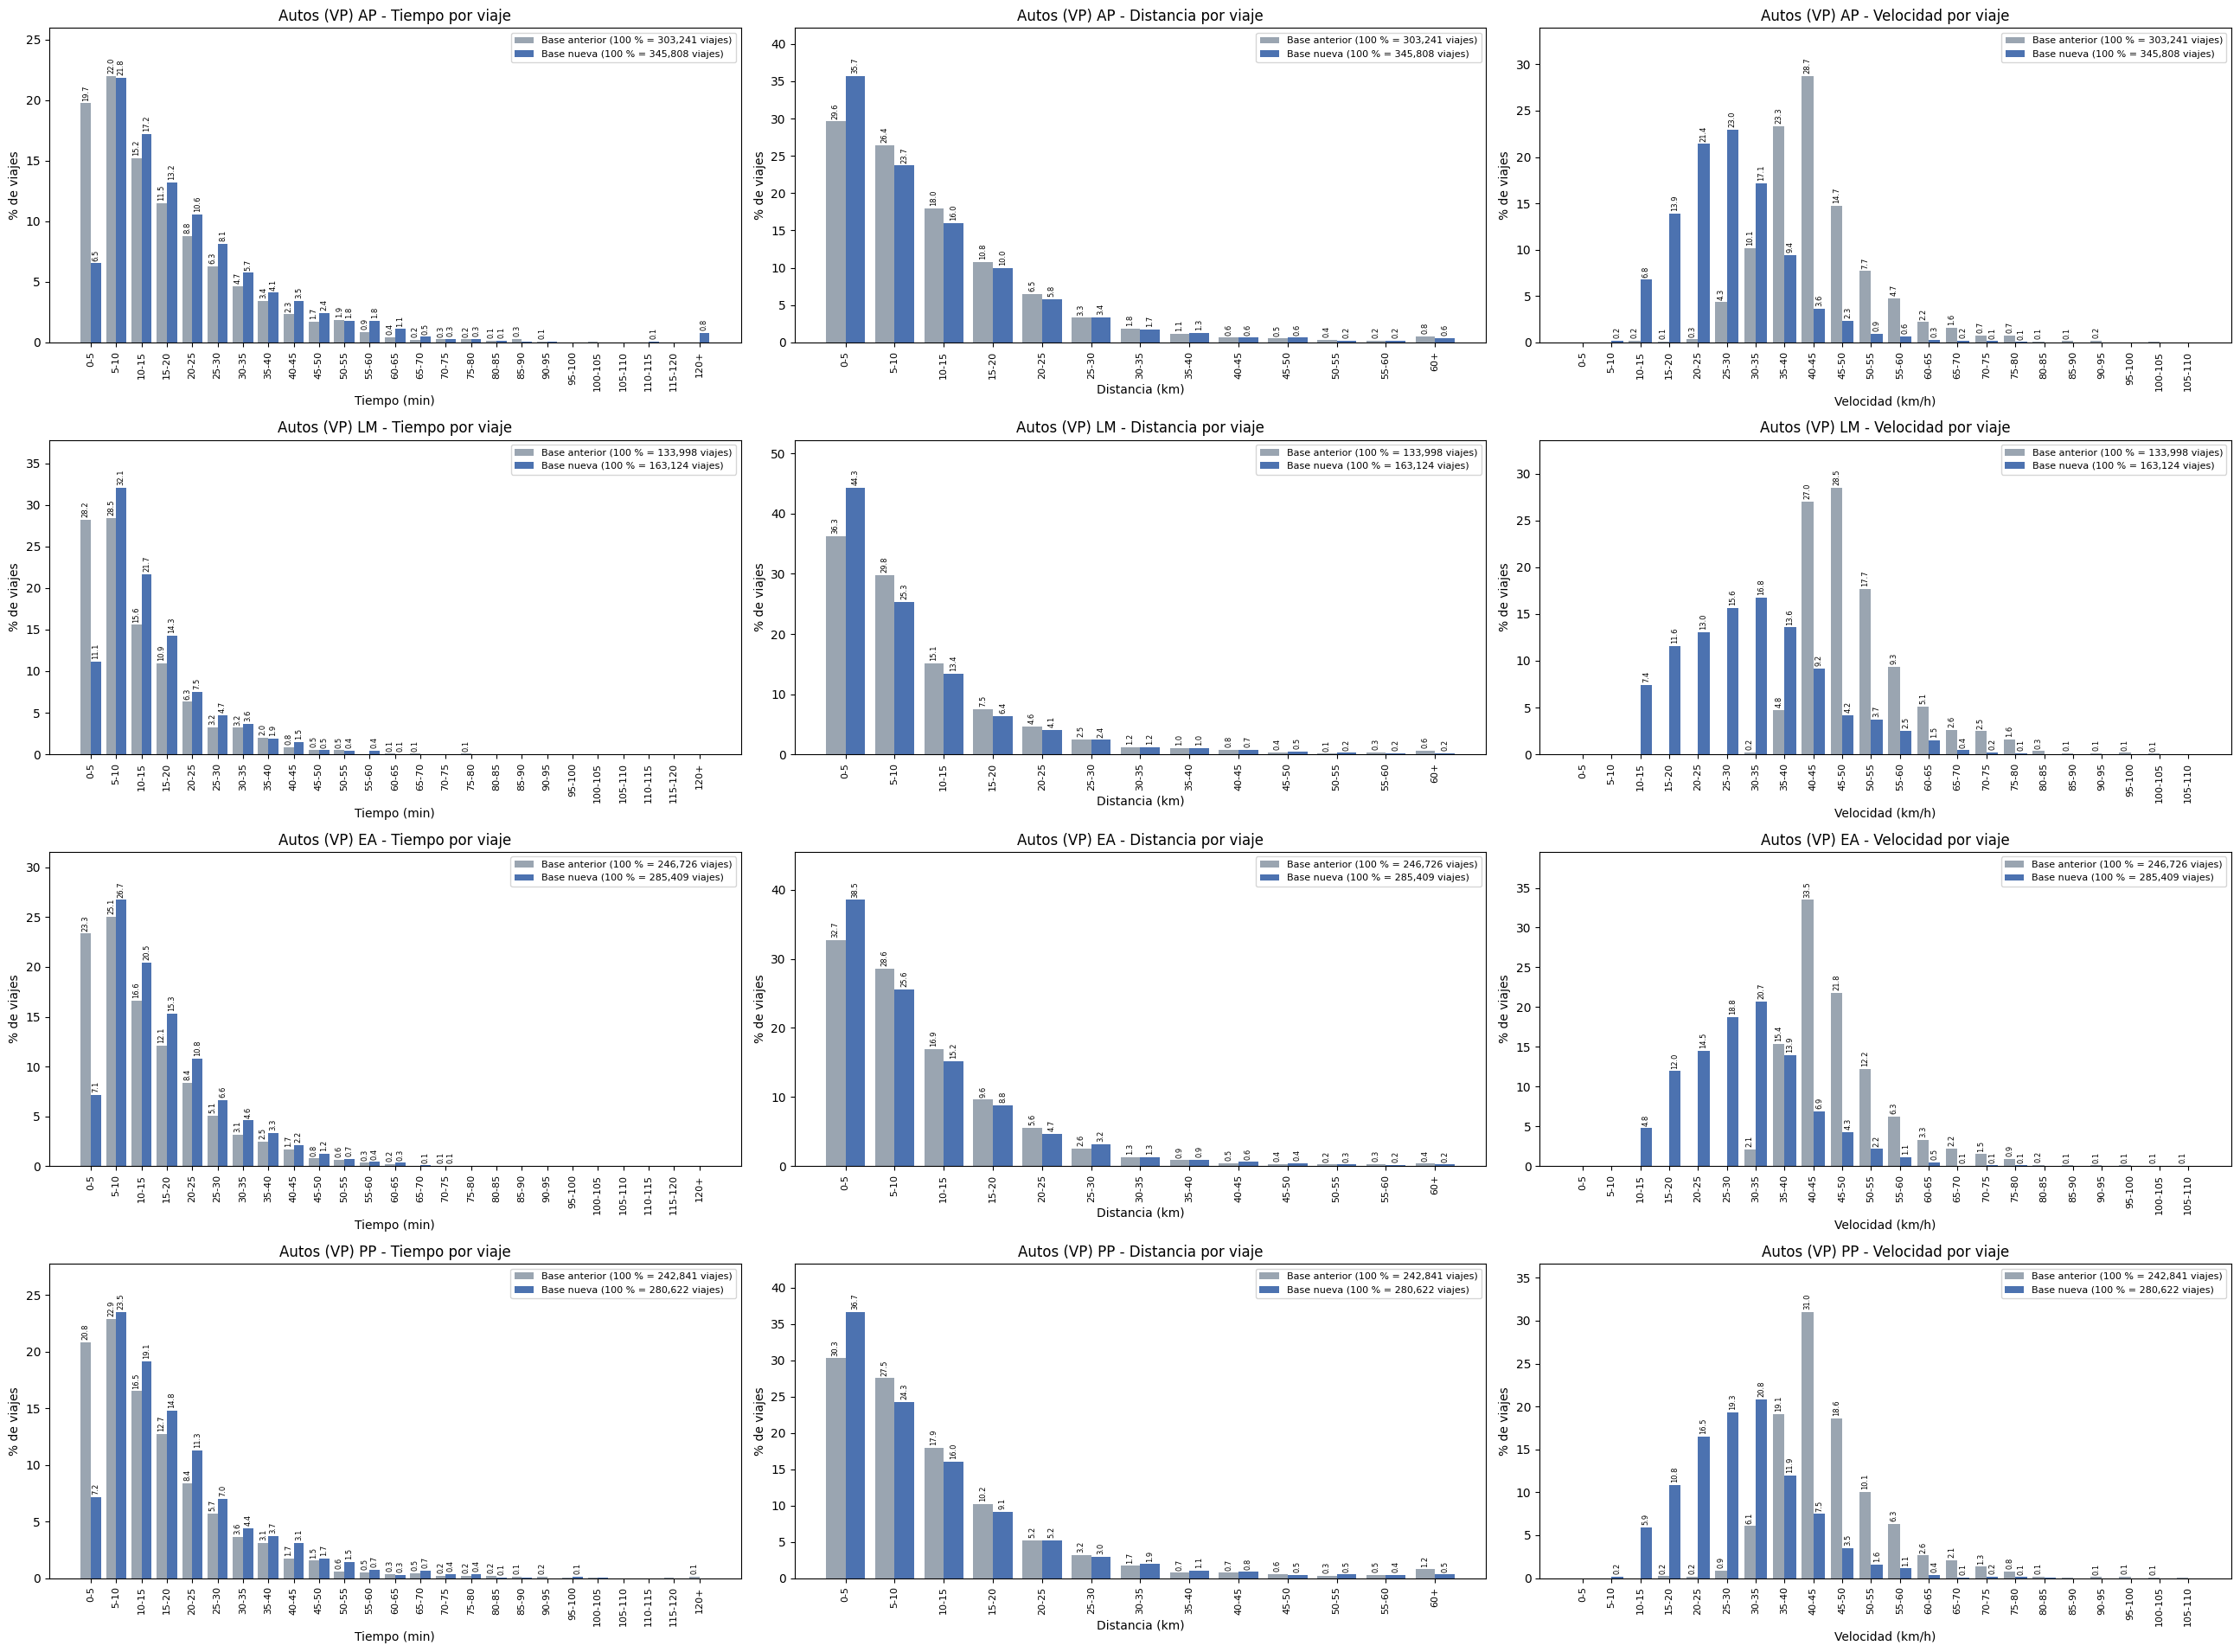

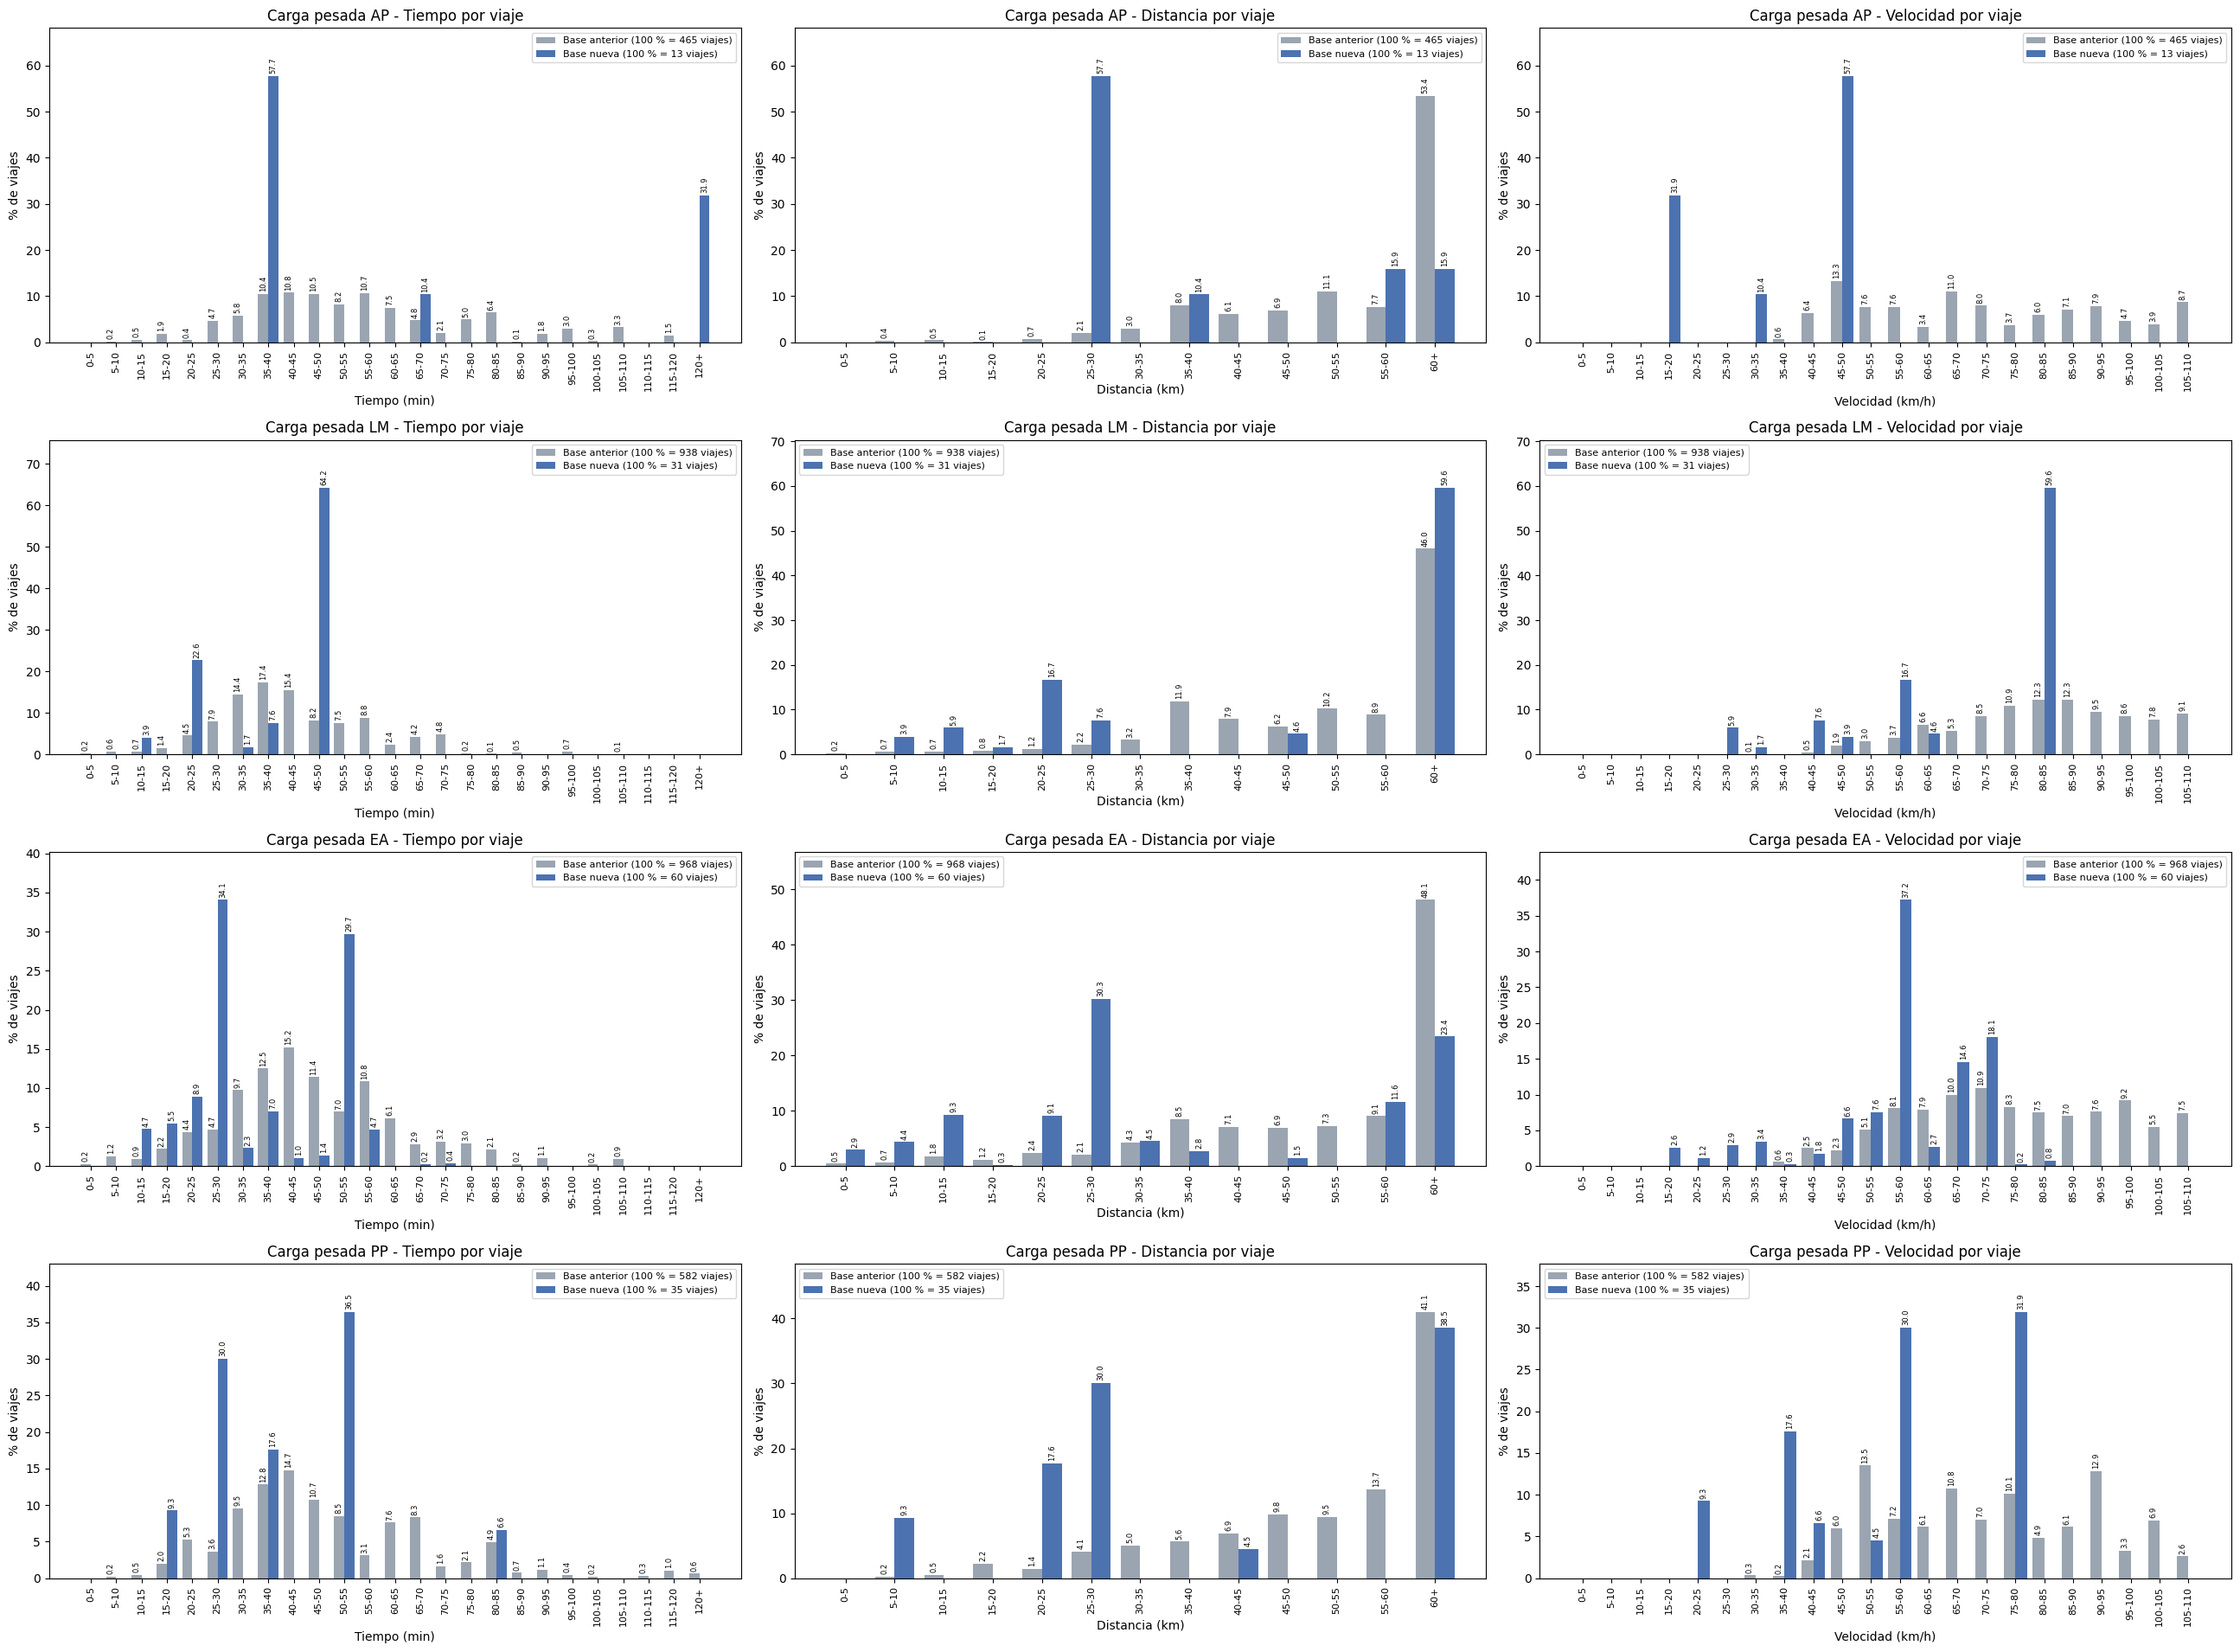

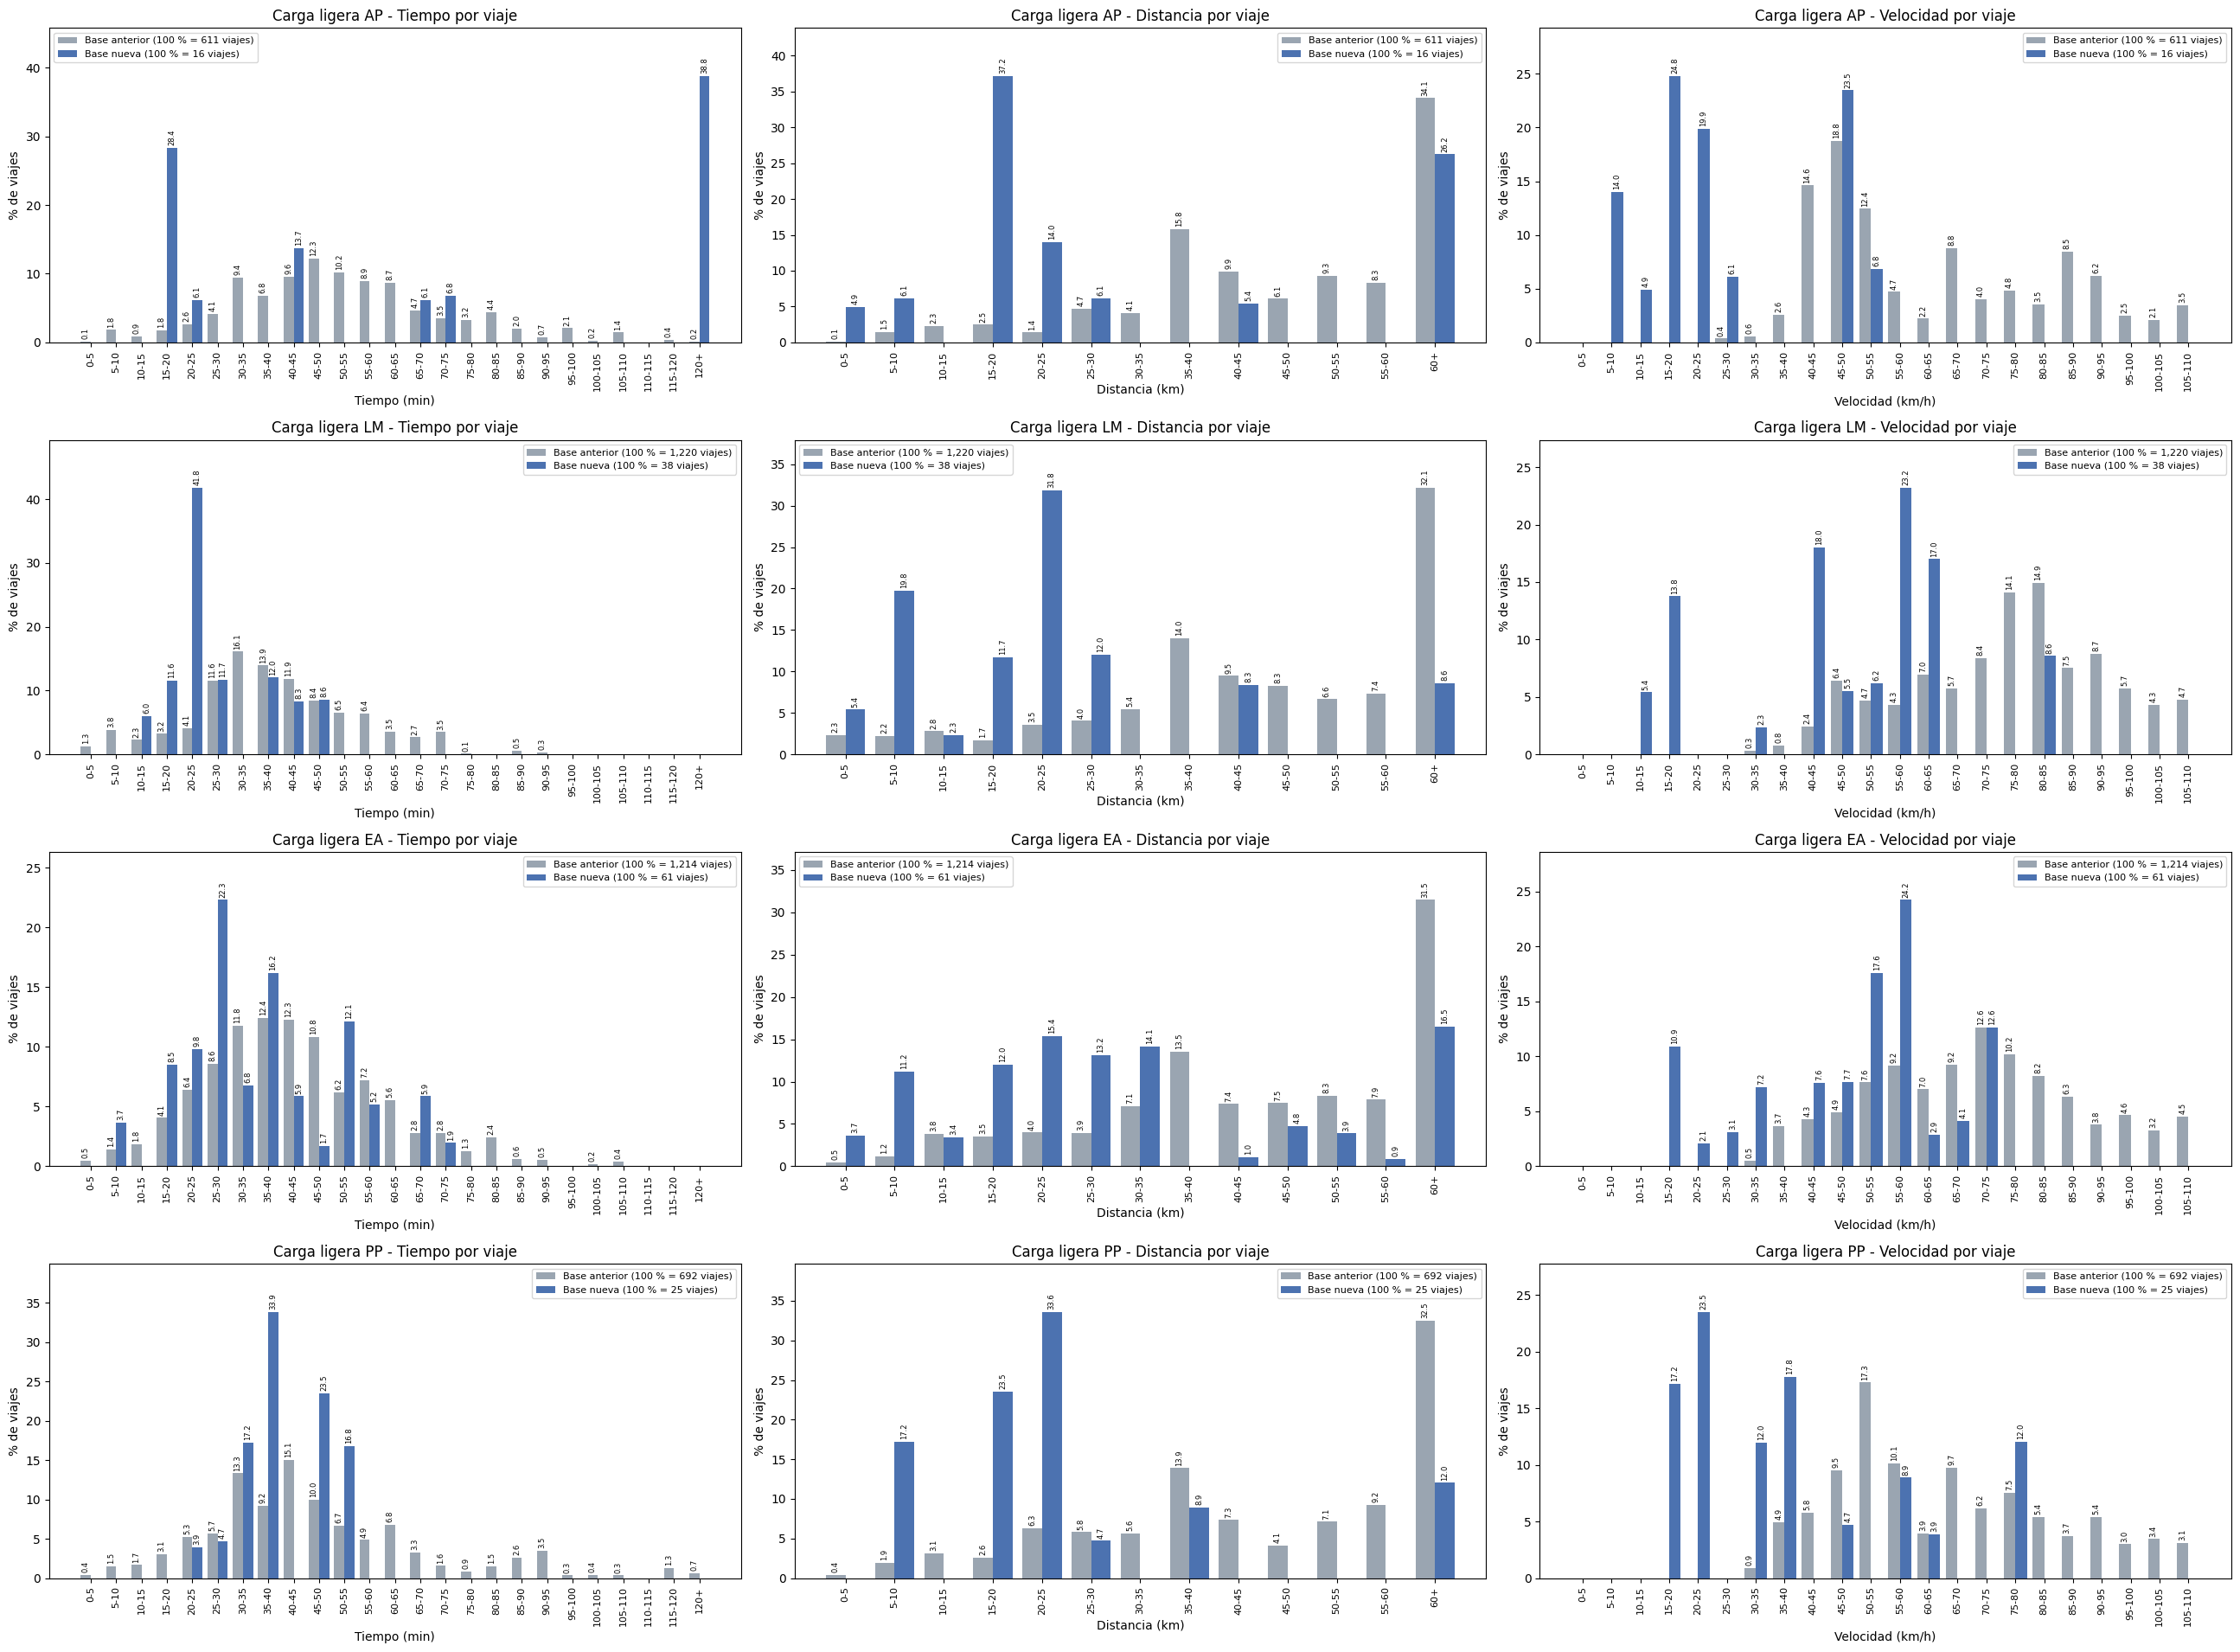

In [16]:
for modo in MODOS:
    fig, axes = plt.subplots(len(PERIODOS), len(VARIABLES), figsize=(26, 4.8 * len(PERIODOS)))
    for fila, p in enumerate(PERIODOS):
        for col, variable in enumerate(VARIABLES):
            series = {base: (viajes[(base, p)][variable], viajes[(base, p)][modo]) for base in CARPETAS}
            ax = axes[fila, col]
            histograma(ax, series, variable, "viajes")
            ax.set_title(f"{NOMBRES_MODO[modo]} {p} - {VARIABLES[variable][0]} por viaje")
    plt.tight_layout()
    plt.show()

## Conclusiones
**Velocidad: es lo que más cambió.** Con la base nueva toda la distribución se corre unos 15 km/h hacia abajo. Por viaje, la mediana baja de 41.9 a 26.7 km/h en AP, de 48.0 a 30.8 en LM, de 44.9 a 30.0 en EA y de 43.9 a 29.2 en PP. Antes casi todos los viajes iban de 35 a 50 km/h; ahora van de 15 a 35 km/h.

**Tiempo: sube.** La mediana por viaje pasa de 12.7 a 16.6 min en AP, de 8.8 a 11.3 en LM, de 10.5 a 13.8 en EA y de 11.8 a 15.1 en PP. Los viajes de menos de 5 min casi desaparecen (en AP, de 19.7 a 6.5 % de los viajes de autos).

**Distancia: casi igual.** La mediana por viaje baja menos de 1 km (en AP de 8.6 a 7.7 km). Hay un poco más de viajes de 0 a 5 km porque ahora entran pares cortos que en la base anterior eran imposibles.

**Viajes que se pueden usar:** con la base nueva entran más viajes (en AP 345,837 contra 304,317), porque ya no hay pares imposibles que quitar.

**Autos (VP):** son casi todos los viajes, así que sus gráficas son prácticamente iguales a las de todos los viajes.

**Carga:** con la base nueva solo quedan de 4 a 40 pares de carga por periodo (de 13 a 61 viajes), contra 229 a 972 pares en la base anterior. Sus distribuciones no son representativas; falta revisar por qué los pares de carga no tienen ruta en la skim nueva.